# Session 7, volcano track: Mount St Helens, 2004 to 2008

🌋 Wednesday 14 October 2026, 10:00 to 11:20, self-guided. Each question has a self-check, and a worked solution to open after you try.

**Learning outcomes.** After this session you can:
- show that a seismogram or catalog you downloaded is the file the provider served;
- say what a seismometer and a network catalog record, and what lies between the ground and each file;
- tell a real extreme from an error, with a physical reason;
- measure how instrument, telemetry, clock and catalog problems bias the regularity of repeating earthquakes;
- turn a catalog into a learning problem without leaking test data;
- write rules and instructions that let another person, or an AI tool, rerun your chain from the raw ComCat and HSR files to the drumbeat clock, and check whether it did.

**Objectives for today.** You will:
- fetch the 2004 to 2008 catalog and six hours of station HSR, and check both;
- screen the catalog and count drumbeats;
- read a spectrogram;
- hunt six problems in a synthetic HSR record and measure the drumbeat clock (drumbeat rate, median spacing, and the coefficient of variation of the spacing) before and after cleaning;
- compute two correlations and name their traps;
- write the chain from catalog to a labelled daily table;
- start the two instruction files you submit on Friday, and test an AI tool on your twin.

**Start (2 min).** In `mlgeo-book` (not `MLGEO2026_UWNETID`), pull and work only in a copy named with your NetID. Do not commit, push or stash.

    cd mlgeo-book
    git pull
    cp book/Chapter2-DataManipulation/lab_s07_volcano.ipynb book/Chapter2-DataManipulation/lab_s07_volcano_UWNETID.ipynb
    pixi run jupyter lab

| Part | What you do | Minutes |
|---|---|---|
| 0 | The system and the question | 3 |
| 1 | Pull the raw data and check it | 10 |
| 2 | A table: the catalog | 8 |
| 3 | A 1D array: one seismometer | 8 |
| 4 | A 2D array: the spectrogram (if time) | 8 |
| 5 | A synthetic twin with planted problems | 15 |
| 6 | Correlations | 8 |
| 7 | From data to a learning problem | 10 |
| 8 | Instructions for an AI tool (if time) | 7 |
| Wrap-up | Three answers and the summary | 3 |

Behind? Skip Parts 4 and 8. Answers replace `None` or empty values; the check below each prints `correct`, a hint, or `not answered yet`.

**Submit** to Canvas, "Session 7: explore your system's data", by Friday 16 October, 9:00: this notebook (.ipynb; HTML optional), the three files of Part 8, and a two- or three-sentence comment on your AI exchange. Completion only: the work does not count toward your grade, but a missing submission costs 10 points.

In [1]:
import hashlib
import io
import json
import os
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from obspy import UTCDateTime, read, read_inventory
from obspy.signal.trigger import classic_sta_lta, trigger_onset
from scipy import signal, stats

import lab_s07_volcano_synthetic as syn
from lab_s07_volcano_checks import check, check_clean, check_expectations, check_pipeline, check_text, print_summary

NETID = ""          # your UW NetID, for example "jdoe": it decides which problems your synthetic twin carries

SNAP = Path("snapshots")          # course copies, committed with the book
DL = Path("s07_my_files")         # your downloads and files (ignored by git)
OFFLINE = bool(os.environ.get("CI")) or os.environ.get("MLGEO_OFFLINE") == "1"
if not (SNAP / "msh_2004-2008.provenance.json").exists():
    raise FileNotFoundError(f"open this notebook from mlgeo-book/book/Chapter2-DataManipulation (now in {Path.cwd()})")
PROV = json.loads((SNAP / "msh_2004-2008.provenance.json").read_text())
plt.rcParams.update({"figure.dpi": 90, "axes.grid": True, "grid.alpha": 0.3})
pd.set_option("display.width", 160)
print("NetID:", NETID or "(empty: you get the class twin, the one the worked solutions use)")
print("offline mode:", OFFLINE)

NetID: (empty: you get the class twin, the one the worked solutions use)
offline mode: True


## Part 0. The system and the question (3 min)

**Do:** read, run the map, write one prediction.

On 23 September 2004, after almost 18 years of quiet, shallow earthquakes began under the crater of Mount St Helens. Small explosions followed; then lava pushed up through the 1980 crater floor as solid dacite spines until 2008 (Dzurisin and others, 2015). From 16 October the earthquakes came at such regular intervals that the Pacific Northwest Seismic Network (PNSN) and the USGS Cascades Volcano Observatory (CVO) "dubbed them 'drumbeat' earthquakes" (Moran and others, 2008, p. 37): "repetitive LF and hybrid earthquakes" (LF: low frequency) that "accompanied the regular rate of extrusion of several dacite spines". They came "only ~20 s apart" until 12 November, then "event spacing increased to ~40 s, and visual inspections show that most events were detected" (p. 39); daily averages stayed "between 40 and 80 s" until April 2005 (p. 37). By 31 January 2008 "seismicity had declined to 1–2 earthquakes per day, a rate similar to pre-eruption levels" (Dzurisin and others).

The drumbeats were watched daily as the pulse of the eruption, yet "drumbeat size and spacing may be more a function of the mechanics of extrusion than of the extrusion rate" (p. 27). More than one million earthquakes were recorded by the end of 2005 and about 8,000 were located (p. 28); "the limited dynamic range of the short-period analog stations was frequently exceeded" (p. 50).

**Labels** ([1.7](../Chapter1-GettingStarted/1.7_get_geodetic_gnss.ipynb)): 📍 In-situ sensor · 🪨 Solid Earth · 🌋 Volcanology for the seismograms; 🗂️ Catalog & compiled product for the catalog.

**Guiding question.** *How regular was the drumbeat clock under the growing lava dome, and how much of that clock do a single seismometer near the vent and the regional earthquake catalog each record?*

**Sources.** Dzurisin and others (2015), *Bulletin of Volcanology* 77, 89, [doi:10.1007/s00445-015-0973-4](https://doi.org/10.1007/s00445-015-0973-4). Moran and others (2008), USGS Professional Paper 1750, chap. 2, p. 27-60, [doi:10.3133/pp17502](https://doi.org/10.3133/pp17502); page numbers refer to this chapter.

Station  Elevation                StartTime                  EndTime
    EDM     1611.0 1980-06-01T00:00:00.0000                      NaN
    HSR     1720.0 1985-08-12T00:00:00.0000                      NaN
    JUN     1049.0 1980-05-08T00:00:00.0000                      NaN
    SEP     2116.0 1997-09-01T00:00:00.0000 2004-10-06T00:00:00.0000
    SHW     1442.0 1972-10-01T00:00:00.0000                      NaN
    YEL     1750.0 1981-10-01T00:00:00.0000 2007-09-18T00:00:00.0000


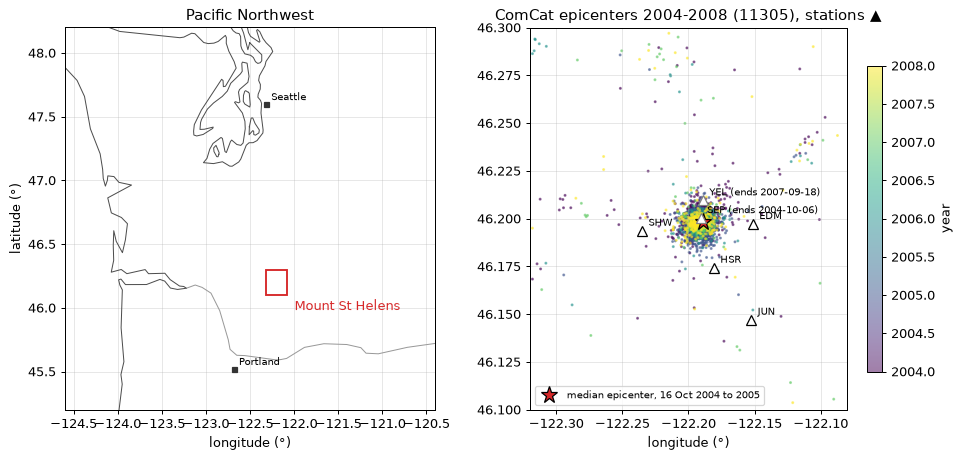

In [2]:
# Map: coastline and borders from Natural Earth (course copy), stations from the EarthScope station service,
# epicenters from the ComCat course copy. matplotlib only.
ne = pd.read_csv(SNAP / "naturalearth_pnw_map.csv")
cat = pd.read_csv(SNAP / "comcat_msh_2004-2008.csv", parse_dates=["time", "updated"])
sta = pd.read_csv(io.StringIO("\n".join(PROV["station"]["station_list"])), sep="|")
sta.columns = [c.strip().lstrip("#").strip() for c in sta.columns]
q = PROV["catalog"]["query"]

fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 5.2))
for (kind, part), g in ne[ne["kind"] != "place"].groupby(["kind", "part"]):
    a1.plot(g["lon"], g["lat"], color="0.3" if kind == "coastline" else "0.6", lw=0.8)
for _, p in ne[ne["kind"] == "place"].iterrows():
    a1.plot(p["lon"], p["lat"], "s", color="0.2", ms=4)
    a1.annotate(p["name"], (p["lon"], p["lat"]), xytext=(4, 3), textcoords="offset points", fontsize=8)
a1.add_patch(plt.Rectangle((q["minlongitude"], q["minlatitude"]), q["maxlongitude"] - q["minlongitude"],
                           q["maxlatitude"] - q["minlatitude"], fill=False, color="C3", lw=1.5))
a1.annotate("Mount St Helens", (q["maxlongitude"], q["minlatitude"]), xytext=(6, -12), textcoords="offset points", color="C3")
a1.set(xlim=(-124.6, -120.4), ylim=(45.2, 48.2), xlabel="longitude (°)", ylabel="latitude (°)", title="Pacific Northwest")
sc = a2.scatter(cat["longitude"], cat["latitude"], s=2, c=cat["time"].dt.year, cmap="viridis", alpha=0.5)
fig.colorbar(sc, ax=a2, label="year", shrink=0.8)
drum = cat[(cat["time"] >= "2004-10-16") & (cat["time"] < "2006-01-01")]
a2.plot(drum["longitude"].median(), drum["latitude"].median(), "*", color="C3", ms=14, mec="k",
        label="median epicenter, 16 Oct 2004 to 2005")
a2.legend(loc="lower left", fontsize=8)
for _, s in sta.iterrows():
    ended = isinstance(s["EndTime"], str) and s["EndTime"].strip()
    a2.plot(s["Longitude"], s["Latitude"], "^", color="0.5" if ended else "k", ms=8, mfc="w")
    a2.annotate(s["Station"] + (f" (ends {s['EndTime'].strip()[:10]})" if ended else ""),
                (s["Longitude"], s["Latitude"]), xytext=(5, 4), textcoords="offset points", fontsize=8)
a2.set(xlim=(q["minlongitude"], q["maxlongitude"]), ylim=(q["minlatitude"], q["maxlatitude"]),
       xlabel="longitude (°)", title=f"ComCat epicenters 2004-2008 ({len(cat)}), stations ▲")
for a in (a1, a2):
    a.set_aspect(1 / np.cos(np.radians(46.2)))
plt.tight_layout()
print(sta[["Station", "Elevation", "StartTime", "EndTime"]].to_string(index=False))

Grey triangles: stations whose metadata end. SEP, on the old dome and closest to the earthquakes: "The October 1 explosion destroyed seismic station SEP" (p. 35). YEL ends in September 2007.

**Prediction.** From the spacing quoted above, how many earthquakes per hour do you expect 2.5 km from the vent in late November 2004?

In [3]:
q0_rate_guess = None    # earthquakes per hour, a number
check("0.guess", q0_rate_guess)

[0.guess] not answered yet


## Part 1. Pull the raw data and check it (10 min)

**Do:** fetch (about 30 s), compare with the course copies, read what the instrument measured. Six questions.

You fetch (1) every earthquake in a box around the volcano, 2004 to 2008, from the USGS Advanced National Seismic System (ANSS) Comprehensive Catalog (ComCat), through the service of the International Federation of Digital Seismograph Networks (FDSN), and (2) six hours of the vertical seismometer HSR, 2.5 km south of the 2004 vent, on 29 November 2004, from EarthScope. If a download fails, the cell uses the course copy in `snapshots/`.

In [4]:
from obspy.clients.fdsn import Client
import requests

DL.mkdir(exist_ok=True)
mine = {"catalog": DL / "comcat_msh_2004-2008_mine.csv", "waveform": DL / "HSR_2004-11-29_mine.mseed"}
course = {"catalog": SNAP / "comcat_msh_2004-2008.csv", "waveform": SNAP / "msh_UW.HSR.EHZ_2004-11-29T15-21.mseed"}

if OFFLINE:
    print("offline mode: no download; the comparison uses the course copies only")
else:
    try:
        r = requests.get("https://earthquake.usgs.gov/fdsnws/event/1/query", timeout=60, params=dict(
            format="csv", minlatitude=46.10, maxlatitude=46.30, minlongitude=-122.32, maxlongitude=-122.08,
            starttime="2004-01-01", endtime="2009-01-01", orderby="time-asc"))
        r.raise_for_status()
        mine["catalog"].write_bytes(r.content)
        print("catalog downloaded:", r.url)
    except Exception as err:
        print("catalog download failed, using the course copy:", err)
    try:
        client = Client("https://service.earthscope.org", timeout=60)
        client.get_waveforms("UW", "HSR", "--", "EHZ", UTCDateTime("2004-11-29T15:00:00"),
                             UTCDateTime("2004-11-29T21:00:00"), filename=str(mine["waveform"]))
        print("waveform downloaded from service.earthscope.org")
    except Exception as err:
        print("waveform download failed, using the course copy:", err)

offline mode: no download; the comparison uses the course copies only


**Was the file modified or corrupted?** Four checks, cheapest first: size, number of rows or samples, first and last records, and the **fingerprint** (SHA-256, Secure Hash Algorithm), a 64-character code computed from every byte: one changed byte changes it. The course copy's is in `snapshots/msh_2004-2008.provenance.json`.

In [5]:
def fingerprint(path):
    return hashlib.sha256(Path(path).read_bytes()).hexdigest()


def describe(path, kind):
    path = Path(path)
    if not path.exists():
        return {"bytes": None, "records": None, "first": None, "last": None, "fingerprint": None}
    if kind == "catalog":
        t = pd.read_csv(path, usecols=["time"])["time"]
        n, first, last = len(t), t.iloc[0], t.iloc[-1]
    else:
        st_ = read(str(path))
        n, first, last = sum(tr.stats.npts for tr in st_), str(st_[0].stats.starttime), str(st_[-1].stats.endtime)
    return {"bytes": path.stat().st_size, "records": n, "first": first, "last": last, "fingerprint": fingerprint(path)[:16] + "..."}


rows = []
for kind in ["catalog", "waveform"]:
    a, b = describe(course[kind], kind), describe(mine[kind], kind)
    recorded = PROV["files"][course[kind].name]["sha256"]
    rows.append({"file": kind, "copy": "course copy", **a, "matches provenance": fingerprint(course[kind]) == recorded})
    rows.append({"file": kind, "copy": "your download", **b,
                 "matches provenance": None if b["fingerprint"] is None else fingerprint(mine[kind]) == recorded})
compare = pd.DataFrame(rows)
compare

,file,copy,bytes,records,first,last,fingerprint,matches provenance
0,catalog,course copy,2149047.0,11305.0,2004-01-14T00:08:23.830Z,2008-12-28T07:25:06.380Z,c3c99041155a7251...,True
1,catalog,your download,NaN,NaN,NaN,NaN,NaN,None
2,waveform,course copy,2545152.0,2038301.0,2004-11-29T15:00:00.000900Z,2004-11-29T20:59:59.999900Z,cc1f7f52caf2fbb2...,True
3,waveform,your download,NaN,NaN,NaN,NaN,NaN,None


**A different fingerprint is not always corruption.** ComCat is revised continuously (relocations, new magnitudes, deleted events); `updated` gives each row's last revision, so look for rows updated after the course copy was retrieved. EarthScope can repackage old waveforms, so equal samples can sit in different bytes.

In [6]:
print("course copy retrieved (UTC):", PROV["retrieved_utc"])
print("rows by year of last revision:", cat["updated"].dt.year.value_counts().sort_index().to_dict())

q1_rows = None        # number of earthquakes (rows) in the course copy of the catalog
q1_same = None        # did your catalog download match the course copy byte for byte? "yes", "no" or "no download"
q1_updated = None     # the latest year in which any row of the catalog was revised
same_truth = "no download" if not mine["catalog"].exists() else ("yes" if fingerprint(mine["catalog"]) == fingerprint(course["catalog"]) else "no")
check("1.rows", q1_rows); check("1.same", q1_same, truth=same_truth); check("1.updated", q1_updated)

course copy retrieved (UTC): 2026-10-14 06:39
rows by year of last revision: {2014: 9, 2016: 11290, 2022: 1, 2025: 5}
[1.rows] not answered yet
[1.same] not answered yet
[1.updated] not answered yet


### Native resolution

HSR is a Geotech S-13 short-period velocity seismometer. Its analog signal was digitized at the network's recording center at "the 100-Hz sample rate used by the PNSN and CVO for all short-period stations" (p. 60). The StationXML lists every stage from ground to stored number: read the stages, the flat band and the gain history.

stage 1: PolesZerosResponseStage        gain        340.4  m/s -> V
stage 2: PolesZerosResponseStage        gain         1047  V -> V
stage 3: PolesZerosResponseStage        gain      0.02399  V -> V
stage 4: CoefficientsTypeResponseStage  gain         1622  V -> counts
sensor: S-13,Velocity Sensor,GEOTECH; sampling rate 100.0 Hz
overall sensitivity: 1.387e+07 counts per m/s at 1.0 Hz

Gain history of this channel (FDSN station text, column 'Scale' = counts per m/s):
      Scale  SampleRate                StartTime                  EndTime
 16924400.0       100.0 1985-08-12T00:00:00.0000 1988-07-21T23:59:59.0000
 33768700.0       100.0 1988-07-22T00:00:00.0000 1994-12-31T23:59:59.0000
535197000.0       100.0 1995-01-01T00:00:00.0000 1995-01-18T23:59:59.0000
134436000.0       100.0 1995-01-19T00:00:00.0000 1997-12-10T23:59:59.0000
134436000.0       100.0 1997-12-11T00:00:00.0000 2002-09-04T23:59:59.0000
138672000.0       100.0 2002-09-05T00:00:00.0000 2004-10-04T23:59:59.0000
 13867200.

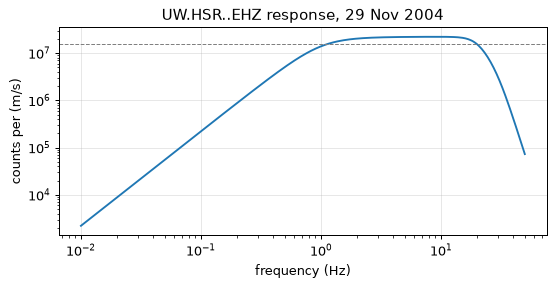

In [7]:
inv = read_inventory(str(SNAP / "msh_UW.HSR.EHZ_response.xml"))
cha = inv[0][0][0]
resp = cha.response
for i, s in enumerate(resp.response_stages, 1):
    print(f"stage {i}: {type(s).__name__:30s} gain {s.stage_gain:>12.4g}  {s.input_units} -> {s.output_units}")
print(f"sensor: {cha.sensor.description}; sampling rate {cha.sample_rate} Hz")
print(f"overall sensitivity: {resp.instrument_sensitivity.value:.4g} counts per m/s at {resp.instrument_sensitivity.frequency} Hz")

f = np.logspace(-2, np.log10(50), 300)
amp = np.abs(resp.get_evalresp_response_for_frequencies(f, output="VEL"))
fig, ax = plt.subplots(figsize=(7, 3))
ax.loglog(f, amp); ax.axhline(amp.max() / np.sqrt(2), color="0.5", ls="--", lw=0.8)
ax.set(xlabel="frequency (Hz)", ylabel="counts per (m/s)", title="UW.HSR..EHZ response, 29 Nov 2004")

print()
print("Gain history of this channel (FDSN station text, column 'Scale' = counts per m/s):")
epochs = pd.read_csv(SNAP / "msh_UW.HSR.EHZ_epochs.txt", sep="|")
epochs.columns = [c.strip().lstrip("#").strip() for c in epochs.columns]
print(epochs[["Scale", "SampleRate", "StartTime", "EndTime"]].to_string(index=False))

The scale drops tenfold on 5 October 2004 (UTC; "a gain reduction on October 4, 2004", appendix 2): equal counts on 3 and 6 October mean ground motions ten times apart. This **calibration change** is recorded only in the metadata.

**The seismogram** is close to raw: counts every 0.01 s, without averaging, gap filling or instrument correction. After sensor, analog filters, telemetry and digitizer, it holds no frequency above half the sampling rate and no motion beyond the telemetry's range.

**The catalog** is derived: arrivals picked on `nst` stations, a hypocenter fitted in a velocity model (`rms`, misfit in s), and a duration magnitude Md from how long the shaking lasted.

In [8]:
q1_nyquist = None   # the highest frequency (Hz) the HSR record can represent
q1_vclip = None     # ground velocity (m/s) at which HSR reaches its largest count: take the largest count in the record
                    # (np.concatenate([tr.data for tr in read(str(course["waveform"]))]).max()), subtract the record's
                    # offset (its median count), and divide by the sensitivity
q1_kind = {"seismogram": None, "catalog": None}   # "raw" or "derived" for each
check("1.nyquist", q1_nyquist); check("1.vclip", q1_vclip)
check("1.kind", q1_kind if all(q1_kind.values()) else None)

[1.nyquist] not answered yet
[1.vclip] not answered yet
[1.kind] not answered yet


*Worked solution below (click ⋯ to open).*

In [9]:
# Worked solution, open after you tried
st_sol = read(str(course["waveform"]))
d_sol = np.concatenate([tr.data for tr in st_sol])
dmax, off = d_sol.max(), np.median(d_sol)
vclip = (dmax - off) / resp.instrument_sensitivity.value
print("Nyquist frequency:", cha.sample_rate / 2, "Hz")
print(f"({dmax} - {off:.0f}) counts / {resp.instrument_sensitivity.value:.4g} counts per m/s = {vclip:.2e} m/s at 1 Hz")
for fq in [2.5, f[np.argmax(amp)]]:
    print(f"at {fq:.1f} Hz the response is {np.interp(fq, f, amp):.3g} counts per m/s, so the record stops at {(dmax - off) / np.interp(fq, f, amp):.2e} m/s")
print("The sensitivity is quoted at 1 Hz, below the plateau, so at drumbeat frequencies the record stops at a smaller")
print("velocity. Moran and others (p. 44) define their larger events by this limit: 'those post-October 2004 events with")
print("amplitudes large enough to clip on station HSR'.")
print("seismogram: raw (counts as digitized); catalog: derived (picks, a velocity model and a magnitude formula).")
print("Rows:", len(cat), "; latest revision year:", cat["updated"].dt.year.max())

Nyquist frequency: 50.0 Hz
(3582 - 162) counts / 1.387e+07 counts per m/s = 2.47e-04 m/s at 1 Hz
at 2.5 Hz the response is 2.1e+07 counts per m/s, so the record stops at 1.63e-04 m/s
at 9.1 Hz the response is 2.21e+07 counts per m/s, so the record stops at 1.55e-04 m/s
The sensitivity is quoted at 1 Hz, below the plateau, so at drumbeat frequencies the record stops at a smaller
velocity. Moran and others (p. 44) define their larger events by this limit: 'those post-October 2004 events with
amplitudes large enough to clip on station HSR'.
seismogram: raw (counts as digitized); catalog: derived (picks, a velocity model and a magnitude formula).
Rows: 11305 ; latest revision year: 2025


```{admonition} If you are stuck
:class: hint
- 'download failed': continue with the course copy; `q1_same` is then `"no download"`.
- 'No such file': open the notebook from `book/Chapter2-DataManipulation`.
```

## Part 2. A table: the earthquake catalog (8 min)

**Do:** write physical limits, then screen the table. Five questions.

One row is one earthquake as the network located it: origin time (UTC), epicenter, depth, magnitude and its type, and the quality of the solution. The next cell prints the ComCat definitions.

In [10]:
doc = PROV["comcat_column_documentation"]
print("source:", doc["url"]); print(doc["note"]); print()
for col in ["time", "depth", "mag", "magType", "nst", "rms", "dmin"]:
    print(f"{col}: {doc[col][:330]}...\n")
cat.head(3).T

source: https://web.archive.org/web/2023id_/https://earthquake.usgs.gov/data/comcat/index.php
The live ComCat event-terms page (https://earthquake.usgs.gov/data/comcat/data-eventterms.php) now redirects; the definitions below are quoted from the Internet Archive copy of the ComCat documentation page.

time: time Data Type Long Integer Description Time when the event occurred. Times are reported in milliseconds since the epoch ( 1970-01-01T00:00:00.000Z ), and do not include leap seconds . In certain output formats, the date is formatted for readability. Additional Information We indicate the date and time when the earthquake initia...

depth: depth Data Type Decimal Typical Values [0, 1000] Description Depth of the event in kilometers. Additional Information The depth where the earthquake begins to rupture. This depth may be relative to the WGS84 geoid, mean sea-level, or the average elevation of the seismic stations which provided arrival-time data for the earthquak...

mag: mag Data 

,0,1,2
time,2004-01-14 00:08:23.830000+00:00,2004-01-14 15:52:54.490000+00:00,2004-01-16 02:53:07.190000+00:00
latitude,46.200167,46.210333,46.1995
longitude,-122.186667,-122.297,-122.186167
depth,0.106,5.732,-0.098
mag,0.5,0.1,-0.8
magType,md,md,md
nst,12,7,8
gap,89.0,92.0,90.0
dmin,0.002732,0.04039,0.02439
rms,0.06,0.05,0.04


```{admonition} 🔒 By hand
:class: attention
No AI tool for the judgment in this step: state what you expect before you run anything, decide with a physical reason, and read the result against your expectation ([1.8](../Chapter1-GettingStarted/1.8_ai_in_your_workflow.md)).
```

**Limits first.** Depth is in km, positive down, possibly from sea level. HSR sits at 1,720 m and SEP at 2,116 m. Which depths and magnitudes are possible for earthquakes under this volcano?

In [11]:
LIMITS = {"depth_km": (None, None), "mag": (None, None)}   # (lowest, highest) you consider physically possible

if None in LIMITS["depth_km"] + LIMITS["mag"]:
    check("2.limits", None)
else:
    check("2.limits", LIMITS)
    out_d = cat[(cat["depth"] < LIMITS["depth_km"][0]) | (cat["depth"] > LIMITS["depth_km"][1])]
    out_m = cat[(cat["mag"] < LIMITS["mag"][0]) | (cat["mag"] > LIMITS["mag"][1])]
    print(f"{len(out_d)} rows outside your depth limits, {len(out_m)} outside your magnitude limits")
    print(out_d[["time", "depth", "depthError", "mag", "nst", "id"]].head(8).to_string(index=False))
    print(out_m[["time", "mag", "magType", "nst", "id"]].head(8).to_string(index=False))

[2.limits] not answered yet


In [12]:
print("missing values per column:"); print(cat.isna().sum()[cat.isna().sum() > 0].to_string()); print()
print("magnitude types:", cat["magType"].value_counts().to_dict())
print("event types:", cat["type"].value_counts().to_dict()); print()
print("rows that share an origin time with another row:")
print(cat[cat["time"].duplicated(keep=False)][["time", "latitude", "longitude", "depth", "mag", "nst", "rms", "id"]].to_string(index=False))
print(); print("five largest magnitudes:")
print(cat.nlargest(5, "mag")[["time", "mag", "magType", "depth", "nst", "id"]].to_string(index=False))
print(); print("depth distribution (km):", cat["depth"].describe().round(2).to_dict())
print("most common depth values (km):", cat["depth"].round(3).value_counts().head(4).to_dict())

missing values per column:
dmin               7238
rms                   9
horizontalError     766
depthError          272
magError             16
magNst                9

magnitude types: {'md': 11299, 'ml': 5, 'mh': 1}
event types: {'earthquake': 11304, 'explosion': 1}

rows that share an origin time with another row:
                            time  latitude   longitude  depth  mag  nst  rms         id
2004-10-04 14:30:03.270000+00:00 46.167667 -122.211833  0.390  1.4    7 0.30 uw10642533
2004-10-04 14:30:03.270000+00:00 46.196667 -122.190833 -0.428  0.3    7 0.03 uw10642498

five largest magnitudes:
                            time  mag magType  depth  nst         id
2004-10-01 17:13:12.530000+00:00  3.9      md -0.828   28 uw10623773
2004-10-01 12:24:39.830000+00:00  3.7      md -1.512   17 uw10620853
2004-10-02 18:57:59.920000+00:00  3.7      md -0.186   10 uw10632868
2004-09-30 09:04:18.840000+00:00  3.6      md -0.594   21 uw10649358
2004-10-01 06:03:45.140000+00:00  3.6      

**One real extreme, one error.** A real extreme is a rare value the Earth produced: keep it. An error is a value the measuring or processing chain produced: flag it, with a reason. Pick one of each.

In [13]:
q2_magtypes = None     # how many distinct magnitude types the catalog uses
q2_missing = None      # the column with the most missing values (its name, as a string)
q2_error_id = None     # the id of one row you would flag as an error rather than a real extreme
q2_largest = None      # the date (YYYY-MM-DD) of the largest earthquake in the box
check("2.magtypes", q2_magtypes); check("2.missing", q2_missing)
check("2.error", q2_error_id); check("2.largest", q2_largest)

[2.magtypes] not answered yet
[2.missing] not answered yet
[2.error] not answered yet
[2.largest] not answered yet


*Worked solution below (click ⋯ to open).*

In [14]:
# Worked solution, open after you tried
from obspy.geodetics import gps2dist_azimuth
print("magnitude types:", cat["magType"].nunique(), cat["magType"].value_counts().to_dict())
print("most missing:", cat.isna().sum().idxmax(), "(dmin, the distance to the nearest station, is blank for most 2004-2008 rows)")
pair = cat[cat["time"].duplicated(keep=False)]
h_km = gps2dist_azimuth(*pair[["latitude", "longitude"]].iloc[0], *pair[["latitude", "longitude"]].iloc[1])[0] / 1000
print(f"Error: rows {pair['id'].tolist()} share an origin time to the hundredth of a second, sit {h_km:.1f} km apart")
print(f"with Md {pair['mag'].tolist()} and nst {pair['nst'].tolist()}. One earthquake entered twice with different picks is far")
print("more likely than two starting in the same hundredth of a second: flag both, check the waveforms.")
big = cat.loc[cat["mag"].idxmax()]
print(f"Real extreme: Md {big['mag']} on {big['time']:%Y-%m-%d %H:%M} UTC, the day of the first explosion: keep it. Its magnitude")
print("is uncertain: that week it became 'increasingly difficult to manually pick earthquakes and determine accurate coda")
print("magnitudes' (Moran and others, p. 33).")
print()
band = cat["depth"].between(-1.9, -1.8)
mode = cat["depth"].round(3).value_counts().idxmax()
print(f"Depth: the shallowest row is {cat['depth'].min():.2f} km; {(cat['depth'] <= -2.0).sum()} rows are at or above -2.00 km;")
print(f"{band.sum()} rows lie between -1.9 and -1.8 km, {(cat['depth'].round(3) == mode).sum()} of them at exactly {mode} km.")
print(f"Median depthError there {cat.loc[band, 'depthError'].median():.2f} km, elsewhere {cat.loc[~band, 'depthError'].median():.2f} km;")
print(f"99th percentile of depth {cat['depth'].quantile(0.99):.2f} km, {(cat['depth'] > 20).sum()} rows deeper than 20 km.")
print("The pile-up is 1.8 to 1.9 km above sea level, about the elevation of the crater floor: the drumbeats were very shallow.")
print("Identical depths to the metre in", (cat["depth"].round(3) == mode).sum(), "separate earthquakes are set not by the ground but by the")
print("location program. Their formal depthError is small, so a small formal error does not mean a correct depth.")
print("The datum matters: Moran and others plot the same events relative to a datum 'roughly 1.1 km above sea level' (fig. 2).")
deep = cat.loc[cat["depth"].idxmax()]
print(f"The {deep['depth']:.0f} km row ({deep['time']:%Y-%m-%d}, {deep['id']}) is far deeper than 99% of the rows: keep it flagged for a")
print(f"separate check (nst {deep['nst']:.0f}, gap {deep['gap']:.0f}°, depthError {deep['depthError']:.1f} km).")
low = cat.loc[cat["mag"].idxmin()]
print(f"The Md {low['mag']} row ({low['time']:%Y-%m-%d}, {low['id']}, nst {low['nst']:.0f}) is the other defensible flag: the next lowest")
print(f"magnitude is {cat['mag'].nsmallest(2).iloc[-1]}. Both are accepted by the self-check, with a reason.")
print(f"Defensible limits: depth from about -2.5 km (stations sit {sta['Elevation'].min() / 1000:.1f} to {sta['Elevation'].max() / 1000:.1f} km above sea level)")
print("to a few tens of km; magnitude from about -2 to 5.")

magnitude types: 3 {'md': 11299, 'ml': 5, 'mh': 1}
most missing: dmin (dmin, the distance to the nearest station, is blank for most 2004-2008 rows)
Error: rows ['uw10642533', 'uw10642498'] share an origin time to the hundredth of a second, sit 3.6 km apart
with Md [1.4, 0.3] and nst [7, 7]. One earthquake entered twice with different picks is far
more likely than two starting in the same hundredth of a second: flag both, check the waveforms.
Real extreme: Md 3.9 on 2004-10-01 17:13 UTC, the day of the first explosion: keep it. Its magnitude
is uncertain: that week it became 'increasingly difficult to manually pick earthquakes and determine accurate coda
magnitudes' (Moran and others, p. 33).

Depth: the shallowest row is -2.01 km; 2 rows are at or above -2.00 km;
1804 rows lie between -1.9 and -1.8 km, 198 of them at exactly -1.834 km.
Median depthError there 0.10 km, elsewhere 0.26 km;
99th percentile of depth 2.78 km, 2 rows deeper than 20 km.
The pile-up is 1.8 to 1.9 km above sea l

```{admonition} If you are stuck
:class: hint
- Times are strings: rerun the map cell in Part 0, which uses `parse_dates`.
- 0 rows outside your limits: negative depth is above the reference level.
```

## Part 3. A 1D array: six hours of one seismometer (8 min)

**Do:** find the sampling interval and gap, count drumbeats, find a real sensor problem. Five questions.

Raw counts from UW.HSR..EHZ, 15:00 to 21:00 UTC on 29 November 2004. Two processes shape the record: drumbeats every few tens of seconds, and occasional larger earthquakes, a separate process (fig. 19 covers this day).

2 Trace(s) in Stream:
UW.HSR..EHZ | 2004-11-29T15:00:00.000900Z - 2004-11-29T20:19:01.860900Z | 100.0 Hz, 1914187 samples
UW.HSR..EHZ | 2004-11-29T20:39:18.869900Z - 2004-11-29T20:59:59.999900Z | 100.0 Hz, 124114 samples
sampling interval: 0.01 s
gap from 2004-11-29T20:19:01.860900Z to 2004-11-29T20:39:18.869900Z: 1217.00 s


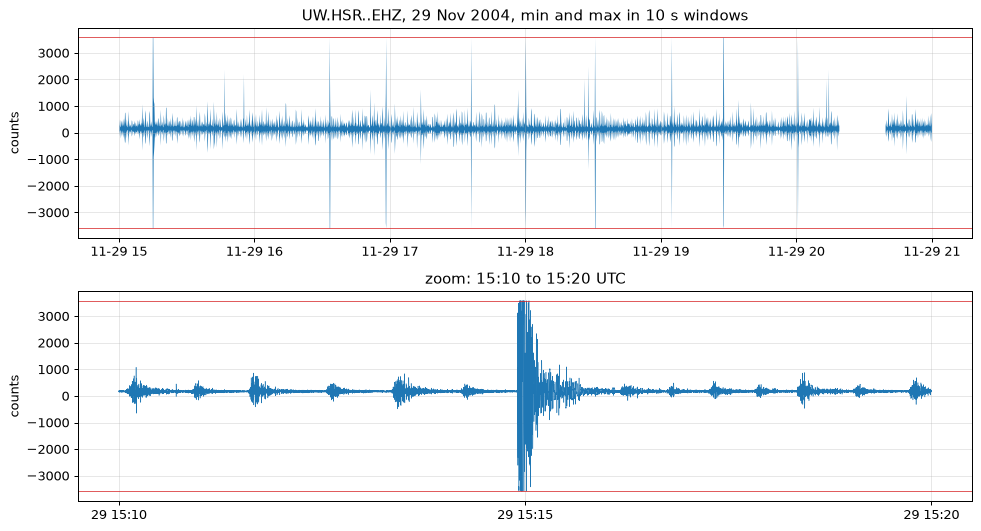

In [15]:
st = read(str(course["waveform"]))
print(st)
print("sampling interval:", st[0].stats.delta, "s")
for g in st.get_gaps():
    print(f"gap from {g[4]} to {g[5]}: {g[6]:.2f} s")

def minmax(tr, sec=10):
    k = int(sec * tr.stats.sampling_rate); n = tr.stats.npts // k * k
    x = tr.data[:n].reshape(-1, k)
    t = [(tr.stats.starttime + i * sec).datetime for i in range(x.shape[0])]
    return t, x.min(1), x.max(1)

fig, (a1, a2) = plt.subplots(2, 1, figsize=(11, 6))
for tr in st:
    t, lo, hi = minmax(tr)
    a1.fill_between(t, lo, hi, color="C0", lw=0)
a1.set(ylabel="counts", title="UW.HSR..EHZ, 29 Nov 2004, min and max in 10 s windows")
z = st.slice(UTCDateTime("2004-11-29T15:10:00"), UTCDateTime("2004-11-29T15:20:00"))[0]
a2.plot(z.times("matplotlib"), z.data, lw=0.4)
a2.xaxis_date(); a2.set(ylabel="counts", title="zoom: 15:10 to 15:20 UTC")
for a in (a1, a2):
    a.axhline(max(tr.data.max() for tr in st), color="C3", lw=0.6); a.axhline(min(tr.data.min() for tr in st), color="C3", lw=0.6)
plt.tight_layout()

In [16]:
# Detector from Moran and others (2008, appendix 2): short-term / long-term average of amplitude over 1 s and 8 s,
# trigger at a ratio of 2.3, then skip 6 s so one earthquake is counted once.
def detect(stream):
    out = []
    for tr in stream:
        x = tr.data.astype(float) - np.median(tr.data)
        cft = classic_sta_lta(x, int(tr.stats.sampling_rate), int(8 * tr.stats.sampling_rate))
        last = -1e9
        for on, _ in trigger_onset(cft, 2.3, 1.0):
            if on - last >= 6 * tr.stats.sampling_rate:
                out.append({"time": (tr.stats.starttime + on * tr.stats.delta).datetime,
                            "peak": float(np.abs(x[on:on + 600]).max())})
                last = on
    return pd.DataFrame(out)

det = detect(st)
hours_with_data = sum(tr.stats.npts for tr in st) / 100 / 3600
rate = len(det) / hours_with_data
intervals = det["time"].diff().dt.total_seconds()
intervals = intervals[intervals < 600]          # drop the interval that spans the data gap
print(f"{len(det)} detections in {hours_with_data:.2f} h of data: {rate:.1f} per hour")
cv_real = intervals.std() / intervals.mean()
print(f"median time between detections {intervals.median():.1f} s; your Part 0 guess: {q0_rate_guess or 'none'} per hour")
print(f"coefficient of variation of the spacing (standard deviation / mean): {cv_real:.2f}, false triggers included")
in_window = cat[(cat["time"] >= "2004-11-29 15:00") & (cat["time"] < "2004-11-29 21:00")]
print(f"ComCat lists {len(in_window)} earthquakes in the same six hours")

615 detections in 5.66 h of data: 108.6 per hour
median time between detections 34.5 s; your Part 0 guess: none per hour
coefficient of variation of the spacing (standard deviation / mean): 0.37, false triggers included


ComCat lists 10 earthquakes in the same six hours


Compare the rate with your guess: the detector also counts bursts and large events, and the published spacing is a daily average.

**A real sensor problem.** Count the samples at the record's extremes, then look at the earthquake at 15:14:55 and the burst at 20:00:32, at HSR and three other crater stations. The cell also lists every second whose energy above 15 Hz exceeds 20 times its median.

largest count 3582 appears 110 times; smallest -3584 appears 334 times
median of the record (the digitizer offset): 162 counts


distance from HSR (km): {'EDM': 3.4, 'JUN': 3.7, 'SHW': 4.7}
EDM: burst starts at 2004-11-29T20:00:32.090000Z
JUN: burst starts at 2004-11-29T20:00:32.080000Z
SHW: no burst between 20:00:30 and 20:00:40
HSR: burst starts at 2004-11-29T20:00:32.050900Z
8 bursts above 15 Hz: ['16:33:15', '16:58:09', '17:35:55', '17:59:59', '18:30:46', '19:04:43', '19:27:37', '20:00:32']
minutes between them: [25, 38, 24, 31, 34, 23, 33]


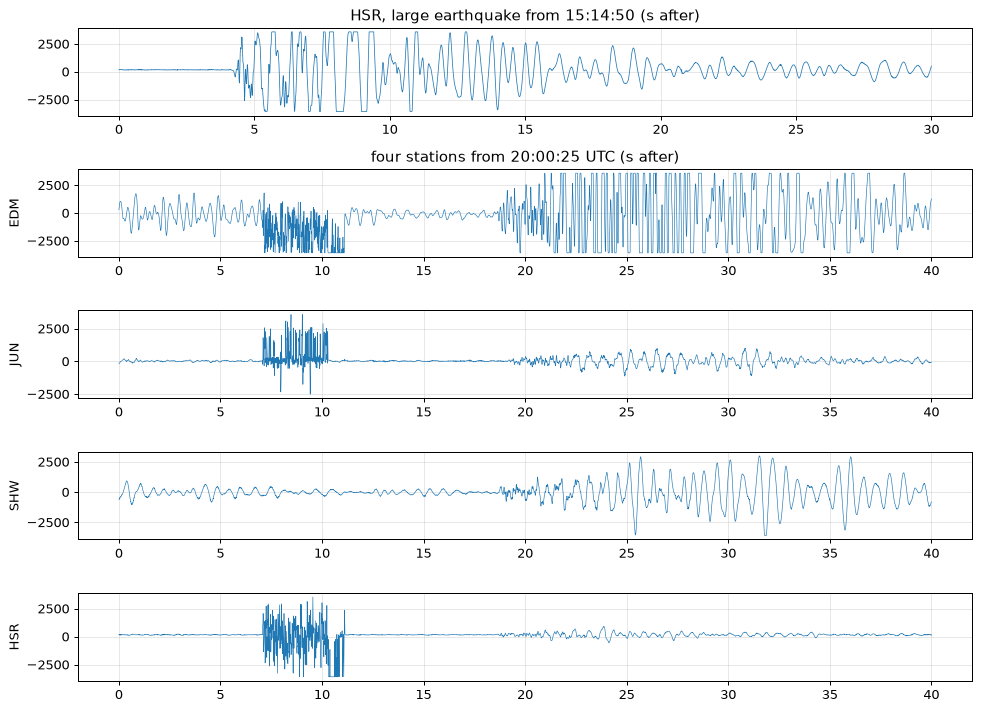

In [17]:
d = np.concatenate([tr.data for tr in st])
print(f"largest count {d.max()} appears {(d == d.max()).sum()} times; smallest {d.min()} appears {(d == d.min()).sum()} times")
print(f"median of the record (the digitizer offset): {np.median(d):.0f} counts")

burst = read(str(SNAP / "msh_UW.EDM-JUN-SHW.EHZ_2004-11-29T2000.mseed")) + st.slice(UTCDateTime("2004-11-29T20:00:00"), UTCDateTime("2004-11-29T20:02:00"))
fig, axes = plt.subplots(1 + len(burst), 1, figsize=(11, 8), sharex=False)
big = st.slice(UTCDateTime("2004-11-29T15:14:50"), UTCDateTime("2004-11-29T15:15:20"))[0]
axes[0].plot(big.times(), big.data, lw=0.6); axes[0].set_title("HSR, large earthquake from 15:14:50 (s after)")
for ax, tr in zip(axes[1:], burst):
    w = tr.slice(UTCDateTime("2004-11-29T20:00:25"), UTCDateTime("2004-11-29T20:01:05"))
    ax.plot(w.times(reftime=UTCDateTime("2004-11-29T20:00:25")), w.data, lw=0.5)
    ax.set_ylabel(tr.stats.station)
from obspy.geodetics import gps2dist_azimuth
loc = sta.set_index("Station")
dist = {s_: gps2dist_azimuth(loc.loc["HSR", "Latitude"], loc.loc["HSR", "Longitude"], loc.loc[s_, "Latitude"], loc.loc[s_, "Longitude"])[0] / 1000
        for s_ in ["EDM", "JUN", "SHW"]}
axes[1].set_title("four stations from 20:00:25 UTC (s after)")
print("distance from HSR (km):", {k: round(v, 1) for k, v in dist.items()})
sos_hf = signal.butter(4, 15.0, btype="highpass", fs=100, output="sos")
for tr in burst:                     # first sample above 15 Hz louder than 20 times that station's median, from 20:00:30
    y = np.abs(signal.sosfiltfilt(sos_hf, tr.data.astype(float) - np.median(tr.data)))
    i0 = int((UTCDateTime("2004-11-29T20:00:30") - tr.stats.starttime) * tr.stats.sampling_rate)
    hit = y[i0:i0 + 1000] > 20 * np.median(y)
    print(f"{tr.stats.station}: " + (f"burst starts at {tr.stats.starttime + (i0 + np.argmax(hit)) * tr.stats.delta}" if hit.any()
                                     else "no burst between 20:00:30 and 20:00:40"))
plt.tight_layout()

# Seconds with energy above 15 Hz more than 20 times the median: candidate bursts
hf = []
for tr in st:
    y = signal.sosfiltfilt(sos_hf, tr.data.astype(float) - np.median(tr.data))
    e = np.sqrt((y[: len(y) // 100 * 100].reshape(-1, 100) ** 2).mean(1))
    loud = np.flatnonzero(e > 20 * np.median(e))
    for g in np.split(loud, np.flatnonzero(np.diff(loud) > 30) + 1) if len(loud) else []:
        hf.append(pd.Timestamp((tr.stats.starttime + int(g[0])).datetime))
bursts_hsr = pd.Series(hf)
print(f"{len(bursts_hsr)} bursts above 15 Hz:", [t.strftime("%H:%M:%S") for t in bursts_hsr])
print("minutes between them:", bursts_hsr.diff().dt.total_seconds().div(60).round(0).dropna().astype(int).tolist())

In [18]:
q3_dt = None          # sampling interval, s
q3_gap_min = None     # length of the data gap, minutes
q3_n_extreme = None   # number of samples equal to the record's largest or smallest value
q3_rate = None        # drumbeats (detections) per hour of data
q3_burst = None       # is the 20:00:32 burst an earthquake? "yes" or "no"
check("3.dt", q3_dt); check("3.gap", q3_gap_min); check("3.extreme", q3_n_extreme)
check("3.rate", q3_rate, truth=rate); check("3.burst", q3_burst)

[3.dt] not answered yet
[3.gap] not answered yet
[3.extreme] not answered yet
[3.rate] not answered yet
[3.burst] not answered yet


*Worked solution below (click ⋯ to open).*

In [19]:
# Worked solution, open after you tried
g = st.get_gaps()[0]
print(f"sampling interval 0.01 s; gap {g[6] / 60:.2f} min ({g[4]} to {g[5]})")
print(f"samples at the extremes: {int(((d == d.max()) | (d == d.min())).sum())}, from the clipped earthquake and from the bursts.")
print(f"The large earthquake at 15:14:55 is cut flat at {d.max()} and {d.min()} counts: the record cannot hold more, so its peak")
print("amplitude, and any magnitude from it, is a lower bound.")
print(f"{rate:.1f} detections per hour of data ({len(det)} in {hours_with_data:.2f} h), median spacing {intervals.median():.1f} s;")
print(f"ComCat located {len(in_window)} of them. After 12 November Moran and others report a spacing of about 40 s with most events detected.")
print("The 20:00:32 burst starts within a few hundredths of a second at HSR, EDM and JUN (3 to 4 km apart), is absent at SHW,")
print("and has no coda. A seismic wave would arrive later at the farther stations: it came through a shared part of the")
print("telemetry, not through the ground.")
mins = bursts_hsr.diff().dt.total_seconds().div(60).dropna()
print(f"The high-frequency search finds {len(bursts_hsr)} such bursts between {bursts_hsr.min():%H:%M} and {bursts_hsr.max():%H:%M},")
print(f"{mins.min():.0f} to {mins.max():.0f} min apart; none is in ComCat. Moran and others list 'noise glitches (including telemetry")
print("and/or Internet dropouts, radio interference, and calibration pulses)' as a reason their detector needed")
print("station-specific filters (appendix 2, p. 60).")

sampling interval 0.01 s; gap 20.28 min (2004-11-29T20:19:01.860900Z to 2004-11-29T20:39:18.869900Z)
samples at the extremes: 444, from the clipped earthquake and from the bursts.
The large earthquake at 15:14:55 is cut flat at 3582 and -3584 counts: the record cannot hold more, so its peak
amplitude, and any magnitude from it, is a lower bound.
108.6 detections per hour of data (615 in 5.66 h), median spacing 34.5 s;
ComCat located 10 of them. After 12 November Moran and others report a spacing of about 40 s with most events detected.
The 20:00:32 burst starts within a few hundredths of a second at HSR, EDM and JUN (3 to 4 km apart), is absent at SHW,
and has no coda. A seismic wave would arrive later at the farther stations: it came through a shared part of the
telemetry, not through the ground.
The high-frequency search finds 8 such bursts between 16:33 and 20:00,
23 to 38 min apart; none is in ComCat. Moran and others list 'noise glitches (including telemetry
and/or Internet dropou

```{admonition} If you are stuck
:class: hint
- No detections: rerun the `detect` cell, which removes the offset and converts to float.
- Rate about 6 percent too low: divide by the hours with data (`hours_with_data`), not by six.
```

## Part 4. A 2D array: the spectrogram (8 min, if you have time)

**Do:** compute a one-hour spectrogram, name its axes and resolution, compare it with published spectra. Four questions.

A spectrogram holds the power (counts² per Hz, plotted in dB) at each frequency (rows) in short windows (columns): here 512 samples, overlapping by half.

array shape (frequencies, times): (257, 1405)
frequency step 0.1953 Hz, time step 2.56 s
median spectrum of all windows: highest above 0.5 Hz at 1.37 Hz
median spectrum of 212 windows with a detection: highest above 0.5 Hz at 1.37 Hz
median spectrum of 1193 windows without: highest above 0.5 Hz at 1.76 Hz
windows with a detection exceed windows without by the largest factor (47) at 5.08 Hz
median spectrum of the first 2.56 s after 106 triggers: highest at 2.34 Hz


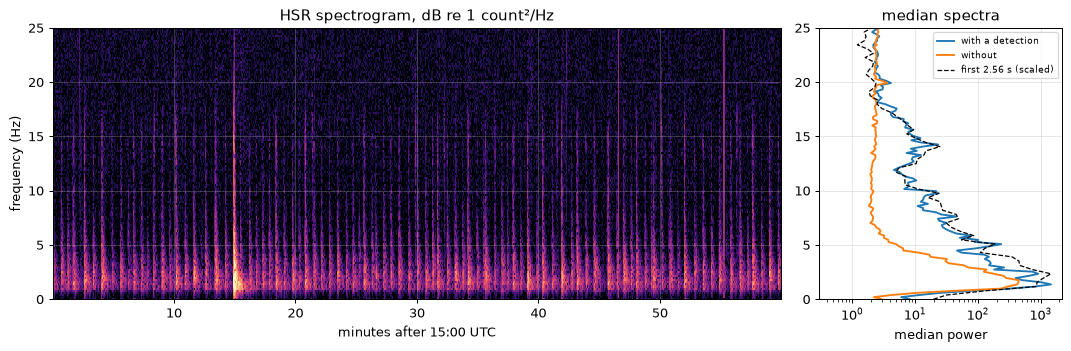

In [20]:
one = st.slice(UTCDateTime("2004-11-29T15:00:00"), UTCDateTime("2004-11-29T16:00:00"))[0]
x = one.data.astype(float) - np.median(one.data)
NPERSEG = 512
freqs, times, S = signal.spectrogram(x, fs=one.stats.sampling_rate, nperseg=NPERSEG, noverlap=NPERSEG // 2)
print("array shape (frequencies, times):", S.shape)
print(f"frequency step {freqs[1] - freqs[0]:.4f} Hz, time step {times[1] - times[0]:.2f} s")
k = freqs > 0.5
t_on = (det["time"] - pd.Timestamp(one.stats.starttime.datetime)).dt.total_seconds().to_numpy()
t_on = t_on[(t_on >= 0) & (t_on < 3600)]
has = np.array([np.any(np.abs(t_on - tc) < NPERSEG / 200) for tc in times])     # a detection onset inside the window
med_all, med_with, med_without = np.median(S, 1), np.median(S[:, has], 1), np.median(S[:, ~has], 1)
for name, m_ in [("all windows", med_all), (f"{has.sum()} windows with a detection", med_with), (f"{(~has).sum()} windows without", med_without)]:
    print(f"median spectrum of {name}: highest above 0.5 Hz at {freqs[k][np.argmax(m_[k])]:.2f} Hz")
ratio = med_with / med_without
print(f"windows with a detection exceed windows without by the largest factor ({ratio[k].max():.0f}) at {freqs[k][np.argmax(ratio[k])]:.2f} Hz")

# Moran and others' way (appendix 2): the spectrum of the first 2.56 s (256 samples) after each trigger
segs = [np.abs(np.fft.rfft(x[int(t * 100):int(t * 100) + 256] * np.hanning(256))) for t in t_on if int(t * 100) + 256 <= len(x)]
f256 = np.fft.rfftfreq(256, 0.01)
esam = np.median(segs, axis=0)
f_peak = f256[1:][np.argmax(esam[1:])]
print(f"median spectrum of the first 2.56 s after {len(segs)} triggers: highest at {f_peak:.2f} Hz")

fig, (a1, a2) = plt.subplots(1, 2, figsize=(12, 4), gridspec_kw={"width_ratios": [3, 1]})
a1.pcolormesh(times / 60, freqs, 10 * np.log10(S + 1e-3), shading="auto", vmin=0, vmax=60, cmap="magma")
a1.set(ylim=(0, 25), xlabel="minutes after 15:00 UTC", ylabel="frequency (Hz)", title="HSR spectrogram, dB re 1 count²/Hz")
a2.semilogx(med_with, freqs, label="with a detection"); a2.semilogx(med_without, freqs, label="without")
a2.semilogx(esam ** 2 / esam.max() ** 2 * med_with.max(), f256, "k--", lw=1, label="first 2.56 s (scaled)")
a2.set(ylim=(0, 25), xlabel="median power", title="median spectra"); a2.legend(fontsize=7)
plt.tight_layout()

Seismicity "was dominated by LF events (peak frequencies in the 2–3-Hz range)" (p. 42), measured on the first 2.56 s after each trigger (appendix 2). Expect a stripe every 30 to 40 s. The earthquake at minute 15 is brighter and broader; its clipped tops add high-frequency power the ground did not produce. Below some frequency the sensor's response falls (Part 1), so the 0.2 Hz ocean microseism is weak here.

Three "peak frequencies" come from one array: the median of all windows (drumbeats, codas and background mixed), the ratio of windows with and without a detection (largest where the background is weakest), and the first 2.56 s after each trigger. Which answers "at what frequency do the drumbeats radiate"?

In [21]:
fw, Pw = signal.welch(x, fs=one.stats.sampling_rate, nperseg=8192)
kl = (fw > 18) & (fw < 22)
f_line = fw[kl][np.argmax(Pw[kl])]
print(f"a narrow line in the one-hour spectrum at {f_line:.2f} Hz, {10 * np.log10(Pw[kl].max() / np.median(Pw[kl])):.1f} dB above the median of 18 to 22 Hz;")
print(f"the response there is {-20 * np.log10(np.interp(f_line, f, amp) / amp.max()):.1f} dB below its maximum")

q4_df = None       # frequency resolution of this spectrogram, Hz
q4_fpeak = None    # frequency (Hz) where the spectrum of the first 2.56 s after each trigger peaks
q4_low = None      # the frequency (Hz) below which the sensor's response falls off
q4_line = """
"""              # what could make a narrow line near 20 Hz, and which test in these data would tell?
check("4.df", q4_df, truth=freqs[1] - freqs[0]); check("4.fpeak", q4_fpeak, truth=f_peak)
f_low = f[np.argmax(amp >= amp.max() / np.sqrt(2))]
check("4.low", q4_low, truth=f_low)
check_text("4.line", q4_line, {"a source you could test": r"station|hour|time|other|compare|constant|always|ground|instrument|electr|telemetry|filter|digitiz",
                               "why the ground is unlikely or likely": r"ground|earthquake|seismic|narrow|single|constant|steady"}, min_words=12)

a narrow line in the one-hour spectrum at 19.98 Hz, 3.3 dB above the median of 18 to 22 Hz;
the response there is 3.1 dB below its maximum
[4.df] not answered yet
[4.fpeak] not answered yet
[4.low] not answered yet
[4.line] not answered yet


*Worked solution below (click ⋯ to open).*

In [22]:
# Worked solution, open after you tried
print(f"frequency resolution = 100 Hz / {NPERSEG} samples = {100 / NPERSEG:.4f} Hz; time step {NPERSEG // 2 / 100} s")
print(f"first 2.56 s after each trigger: peak at {f_peak:.2f} Hz, inside the 2-3 Hz Moran and others report for LF drumbeats.")
print(f"The median of all windows peaks at {freqs[k][np.argmax(med_all[k])]:.2f} Hz: background and codas set it, not the drumbeat onsets.")
print(f"The with/without ratio peaks at {freqs[k][np.argmax(ratio[k])]:.2f} Hz because the background without detections is strongest")
print(f"near {freqs[k][np.argmax(med_without[k])]:.2f} Hz, which shrinks the ratio there. A ratio measures contrast, not where energy is radiated.")
print(f"the response is within 3 dB of its maximum from {f_low:.2f} Hz to about 20 Hz (StationXML)")
print(f"The {f_line:.2f} Hz line: no source we have explains it, so treat it as an open question. Tests: is it present in every hour")
print("and in the gap-free minutes without drumbeats; is it at the same frequency on EDM, JUN and SHW (two-minute file);")
print("does its amplitude follow the ground motion? A line that stays at one frequency whatever the ground does is more likely")
print("made by the recording chain than by the volcano, but only those tests can say.")

frequency resolution = 100 Hz / 512 samples = 0.1953 Hz; time step 2.56 s
first 2.56 s after each trigger: peak at 2.34 Hz, inside the 2-3 Hz Moran and others report for LF drumbeats.
The median of all windows peaks at 1.37 Hz: background and codas set it, not the drumbeat onsets.
The with/without ratio peaks at 5.08 Hz because the background without detections is strongest
near 1.76 Hz, which shrinks the ratio there. A ratio measures contrast, not where energy is radiated.
the response is within 3 dB of its maximum from 1.16 Hz to about 20 Hz (StationXML)
The 19.98 Hz line: no source we have explains it, so treat it as an open question. Tests: is it present in every hour
and in the gap-free minutes without drumbeats; is it at the same frequency on EDM, JUN and SHW (two-minute file);
does its amplitude follow the ground motion? A line that stays at one frequency whatever the ground does is more likely
made by the recording chain than by the volcano, but only those tests can say.


```{admonition} If you are stuck
:class: hint
- One color only: plot `10*np.log10(S)` and keep `vmin`, `vmax`.
- `f` or `amp` undefined: run the response cell in Part 1.
```

## Part 5. A synthetic twin with planted problems (15 min)

**Do:** (a) list what can go wrong, (b) hunt, (c) measure the drumbeat clock, (d) reflect.

The twin imitates three hours of HSR with a known truth: counts at 100 samples per second, noise, drumbeats, three larger earthquakes, and the event list (time, peak amplitude within 6 s, magnitude, magnitude type, id). Like the real record it clips the large earthquakes; that is the instrument, not a planted problem. Your NetID chooses which six problems of real volcano records are planted, and where (empty: the class twin of the worked solution).

**The drumbeat clock** is the rate of drumbeats (magnitude below 2.0) per hour of data, their median spacing, and the coefficient of variation (CV) of the spacing, standard deviation over mean: near 0 for a clock, near 1 for a random (Poisson) process. The twin's spacing (32 to 45 s) and CV (0.15 to 0.28) are chosen, not measured.

```{admonition} 🔒 By hand
:class: attention
No AI tool for the judgment in this step: state what you expect before you run anything, decide with a physical reason, and read the result against your expectation ([1.8](../Chapter1-GettingStarted/1.8_ai_in_your_workflow.md)).
```

**(a) Before you look**, list the problems a seismometer on a volcano, its telemetry, its recording computer, and the people and programs that build an event list could introduce.

In [23]:
q5a_expect = []    # e.g. ["...", "..."]
check_expectations(q5a_expect)

[5a] not answered yet


In [24]:
twin = syn.Twin(NETID)
tmin = twin.times_s() / 60
ev = twin.events.copy()
ev["minute"] = twin.minutes(ev["time"])
print(f"twin '{twin.tag}': start {twin.start}, {twin.n} samples at {syn.FS:.0f} per second, {len(ev)} listed events")
ev.head()

twin 'class': start 2005-01-01 00:00:00+00:00, 1080000 samples at 100 per second, 257 listed events


,time,peak_counts,mag,magType,id,minute
0,2005-01-01T00:00:20.00Z,328,0.8,md,sy100006,0.333333
1,2005-01-01T00:00:56.21Z,296,1.0,md,sy100015,0.936833
2,2005-01-01T00:01:42.15Z,242,0.9,md,sy100023,1.702500
3,2005-01-01T00:02:21.93Z,693,1.3,md,sy100030,2.365500
4,2005-01-01T00:02:55.13Z,589,1.2,md,sy100033,2.918833


**(b) Hunt.** Read each panel against what the ground and instrument can do; `zoom(minute)` shows the raw twin.
1. Min and max in 10 s windows.
2. Noise: median distance from the median count, per minute.
3. Magnitude minus the amplitude magnitude 1 + log10(peak / 300): 300 counts is about Md 1.0 at HSR (appendix 2); one unit per factor of 10 is our assumption. Clipped events sit high, and for real drumbeats "long codas ... yield overly large Md values relative to magnitudes determined using amplitudes" (p. 44).
4. Listed time minus the detected onset (s): about −0.3 s when they agree, because the detector triggers during each event's 0.4 s rise. On real events under 300 counts "our algorithm commonly triggered on the S-wave" (p. 60).
5. Time since the previous listed event (s).

A drumbeat just before a larger earthquake takes that earthquake's amplitude into its 6 s window: a real overlap, keep it.

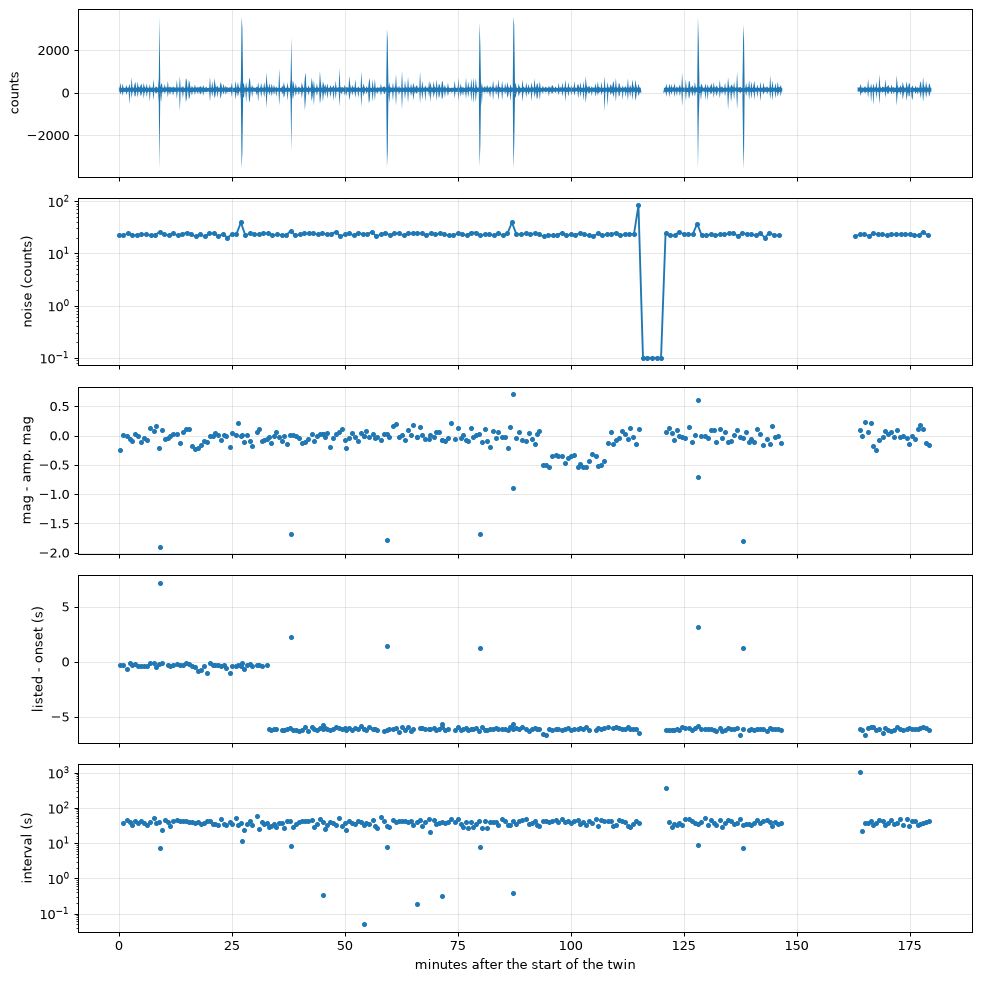

In [25]:
fig, ax = plt.subplots(5, 1, figsize=(11, 11), sharex=True)
w = pd.Series(twin.wave)
g10 = w.groupby((tmin * 6).astype(int))
ax[0].fill_between(g10.min().index / 6, g10.min(), g10.max(), lw=0); ax[0].set_ylabel("counts")
lvl = w.groupby(tmin.astype(int)).apply(lambda v: np.nanmedian(np.abs(v - np.nanmedian(v))) if v.notna().any() else np.nan)
ax[1].semilogy(lvl.index, lvl.values + 0.1, ".-"); ax[1].set_ylabel("noise (counts)")
ev["resid"] = ev["mag"] - (1 + np.log10(ev["peak_counts"].astype(float) / 300))
ax[2].plot(ev["minute"], ev["resid"], "."); ax[2].set_ylabel("mag - amp. mag")
ev["lag_s"] = twin.onset_lags(ev)
ax[3].plot(ev["minute"], ev["lag_s"], "."); ax[3].set_ylabel("listed - onset (s)")
ev["dt_s"] = ev["minute"].diff() * 60
ax[4].semilogy(ev["minute"], ev["dt_s"].clip(lower=0.01), "."); ax[4].set_ylabel("interval (s)")
ax[4].set_xlabel("minutes after the start of the twin")
plt.tight_layout()


def zoom(minute, width=1.0):
    k = (tmin >= minute - width / 2) & (tmin < minute + width / 2)
    plt.figure(figsize=(10, 2.5)); plt.plot(tmin[k], twin.wave[k], lw=0.5)
    for m in ev["minute"][(ev["minute"] > minute - width / 2) & (ev["minute"] < minute + width / 2)]:
        plt.axvline(m, color="C3", lw=0.6)
    plt.xlabel("minute"); plt.ylabel("counts"); plt.title(f"twin around minute {minute} (red: listed events)")

In [26]:
x = twin.wave
fin = x[np.isfinite(x)]
print(f"largest count {fin.max():.0f} appears {(fin == fin.max()).sum()} times; smallest {fin.min():.0f} appears {(fin == fin.min()).sum()} times")

def runs(mask, min_len=100):
    e = np.flatnonzero(np.diff(np.r_[0, mask.astype(int), 0]))
    return [(float(round(a / 6000, 2)), float(round(b / 6000, 2))) for a, b in zip(e[::2], e[1::2]) if b - a >= min_len]

print("runs of exact zeros longer than 1 s (minutes):", runs(x == 0))
print("runs with no samples (NaN) (minutes):", runs(np.isnan(x), 1))
step = (lvl / lvl.shift(1)).dropna()
print("minutes where the noise level jumps by more than a factor 1.5:", step[(step > 1.5) | (step < 1 / 1.5)].round(2).to_dict())
# your check: which rows are less than 2 s after the previous one, and what do they share?

print("events whose magnitude is more than 1 unit below what their amplitude predicts:")
print(ev.loc[ev["resid"] < -1, ["time", "minute", "peak_counts", "mag", "id"]].to_string())

largest count 3582 appears 215 times; smallest -3584 appears 194 times
runs of exact zeros longer than 1 s (minutes): [(115.57, 120.79)]
runs with no samples (NaN) (minutes): [(146.87, 163.65)]
minutes where the noise level jumps by more than a factor 1.5: {27: 1.7, 28: 0.56, 87: 1.62, 88: 0.59, 115: 3.61, 116: 0.0, 121: inf, 128: 1.61, 129: 0.59}
events whose magnitude is more than 1 unit below what their amplitude predicts:
                        time      minute  peak_counts  mag        id
14   2005-01-01T00:09:04.68Z    9.078000         3728  0.2  sy100118
62   2005-01-01T00:38:04.40Z   38.073333         2919  0.3  sy100454
99   2005-01-01T00:59:22.04Z   59.367333         3622  0.3  sy100705
134  2005-01-01T01:19:51.77Z   79.862833         3597  0.4  sy100956
218  2005-01-01T02:18:13.06Z  138.217667         3728  0.3  sy101546


Record each problem: `kind`, one of `calibration pulse`, `zeros`, `dropout`, `gain change`, `telemetry burst`, `clock jump`, `duplicate`, `magnitude method change`, `clipping`, `spike`, `unit change`, `drift`; `minute` (start of a stretch); `why` it is physically implausible. Not every kind is planted; clipping never is. The three larger earthquakes are real.

In [27]:
findings = [
    # {"kind": "zeros", "minute": 12.3, "why": "..."},
]
SHOW_MISSED = False     # set to True after a second look, to see which kinds you missed
twin.score(findings, show_missed=SHOW_MISSED);

not answered yet


**(c) The drumbeat clock three ways:** truth, as given, and after your cleaning. Each line of `clean` is one decision; `EXCLUDE` lists no-data stretches (start, end minute) so that intervals across them are not counted.

In [28]:
def clean(events):
    e = events.copy()
    # e = e[~((e["dt_s"] < 2) & (e["mag"] == e["mag"].shift(1)))]       # duplicates: same magnitude, < 2 s apart
    # e = e[~((e["resid"] < -1) & (e["mag"] < 0.6))]   # bursts or pulses listed as events: zoom(minute) on each first;
    #                                                   # a drumbeat just before a larger earthquake also has a low residual
    # shift = (listed - onset after the jump) - (listed - onset before), both from panel 4, in seconds
    # e.loc[e["minute"] >= JUMP_MINUTE, "minute"] -= shift / 60              # clock jump: move later rows back by shift
    e["time"] = (twin.start + pd.to_timedelta(e["minute"], unit="m")).dt.strftime("%Y-%m-%dT%H:%M:%S.%fZ")
    return e

EXCLUDE = []        # e.g. [(12.0, 15.5)]

cleaned = clean(ev)
three = pd.DataFrame([twin.clock(twin.truth_events, label="truth"),
                      twin.clock(twin.events, label="contaminated"),
                      twin.clock(cleaned, EXCLUDE, label="after your cleaning")]).set_index("label")
print(three.to_string())
changed = bool(EXCLUDE) or len(cleaned) != len(ev) or not np.allclose(cleaned["minute"].to_numpy(), ev["minute"].to_numpy())
check_clean(three, changed)

                     n_drumbeats  rate_per_hour  median_interval_s     cv
label                                                                    
truth                        280           93.3               38.6  0.152
contaminated                 254           84.7               38.3  1.601
after your cleaning          254           84.7               38.3  1.601
[5.clean] not answered yet


**(d) Reflect.** For each problem: did it bias the clock (rate, spacing, CV) or something else, such as a magnitude or an amplitude? Which could cleaning not undo, and what would recover them?

In [29]:
q5d = """
"""
check_text("5d", q5d, {"which problems left the clock unchanged": r"clip|gain|magnitude|amplitude",
                        "what removed data for good": r"cannot|can't|lost|never|undo|recover",
                        "the rate as well as the spacing": r"rate|per hour|missing|gap"})

[5d] not answered yet


*Worked solution below (click ⋯ to open).*

In [30]:
# Worked solution, open after you tried
sol_twin = syn.Twin("")                  # the class twin
print("planted in the class twin:", sol_twin.planted)
e = sol_twin.events.copy(); e["minute"] = sol_twin.minutes(e["time"])
e["resid"] = e["mag"] - (1 + np.log10(e["peak_counts"].astype(float) / 300))
e["dt_s"] = e["minute"].diff() * 60
e["lag_s"] = sol_twin.onset_lags(e)
xs = sol_twin.wave
z_runs, n_runs = runs(xs == 0), runs(np.isnan(xs), 1)
print("exact zeros (minutes):", z_runs, "  no samples:", n_runs)

# Clock: listed - onset, compared with its value at the start of the record
base = e["lag_s"].iloc[:20].median()
rough = e.loc[(e["lag_s"].rolling(9, center=True, min_periods=5).median() - base).abs() > 2, "minute"].min()
jump_at = e.loc[(e["minute"] >= rough - 5) & ((e["lag_s"] - base).abs() > 2), "minute"].min()
before, after = e.loc[e["minute"] < jump_at, "lag_s"].median(), e.loc[e["minute"] >= jump_at, "lag_s"].median()
shift = after - before
print(f"clock: listed - onset is {before:.2f} s before minute {jump_at:.1f} and {after:.2f} s after:")
print(f"from there the listed times run {abs(shift):.1f} s {'late' if shift > 0 else 'early'}: subtract the shift ({shift:.2f} s),")
print(f"which moves them {abs(shift):.1f} s {'earlier' if shift > 0 else 'later'}")

dup = (e["dt_s"] < 2) & (e["mag"] == e["mag"].shift(1))
print("duplicates:", int(dup.sum()), "at minutes", e.loc[dup, "minute"].round(1).tolist())
glitch = (e["resid"] < -1) & (e["mag"] < 0.6) & ~dup
print("listed glitches (amplitude far above the magnitude):", e.loc[glitch, "minute"].round(1).tolist())
big_listed = e.loc[e["mag"] >= 2.0, "minute"].to_numpy()
before_big = np.array([any(0 < b - m < 0.1 for b in big_listed) for m in e["minute"]], dtype=bool)   # within 6 s before
ov = e.loc[before_big & (e["mag"] < 2.0), ["minute", "peak_counts", "mag", "resid"]].round(2)
print("drumbeats listed within seconds before a large earthquake:"); print(ov.to_string())
print("  their 6 s amplitude window holds the earthquake, so their amplitude is too large for their magnitude:")
print("  a real overlap, neither a duplicate nor a glitch. Keep them.")

quiet = e[~dup & ~glitch & (e["mag"] < 2.0) & (e["resid"] > -1)]
r2 = quiet.groupby((quiet["minute"] // 2) * 2)["resid"].median()
low = r2[r2 < r2.median() - 0.3]
block = (float(low.index.min()), float(low.index.max()) + 2) if len(low) else None
lvl_s = pd.Series(xs).groupby((np.arange(len(xs)) / 6000).astype(int)).apply(lambda v: np.nanmedian(np.abs(v - np.nanmedian(v))) if v.notna().any() else np.nan)
if block:
    print(f"magnitudes {r2.median() - low.median():.2f} low from minute {block[0]:.0f} to {block[1]:.0f}, while the noise level there is",
          f"{lvl_s.loc[int(block[0]):int(block[1])].median():.0f} counts against {lvl_s.median():.0f} overall: amplitudes unchanged.")

c = e[~dup & ~glitch].copy()
c.loc[c["minute"] >= jump_at, "minute"] -= shift / 60
c["time"] = (sol_twin.start + pd.to_timedelta(c["minute"], unit="m")).dt.strftime("%Y-%m-%dT%H:%M:%S.%fZ")
print(f"after the correction, listed - onset after minute {jump_at:.0f}: {sol_twin.onset_lags(c).loc[c['minute'] > jump_at].median():.2f} s")
excl = [(a - 0.2, b + 0.2) for a, b in z_runs + n_runs]
print(pd.DataFrame([sol_twin.clock(sol_twin.truth_events, label="truth"), sol_twin.clock(sol_twin.events, label="contaminated"),
                    sol_twin.clock(c, excl, label="cleaned")]).set_index("label").to_string())

sol_findings = []
if z_runs: sol_findings.append({"kind": "zeros", "minute": z_runs[0][0], "why": "minutes of exact zeros; a live sensor always records noise around its offset"})
if n_runs: sol_findings.append({"kind": "dropout", "minute": n_runs[0][0], "why": "no samples at all for many minutes"})
if pd.notna(jump_at): sol_findings.append({"kind": "clock jump", "minute": float(jump_at), "why": "listed times shift by a constant from here on"})
if dup.any(): sol_findings.append({"kind": "duplicate", "minute": float(e.loc[dup, "minute"].iloc[0]), "why": "same magnitude and amplitude under 2 s apart"})
if glitch.any(): sol_findings.append({"kind": "telemetry burst", "minute": float(e.loc[glitch, "minute"].iloc[0]), "why": "boxy high-frequency noise, no coda, tiny magnitude"})
if block: sol_findings.append({"kind": "magnitude method change", "minute": block[0], "why": "magnitudes low for a block while amplitudes and noise are not"})
sol_twin.score(sol_findings, who="worked solution", show_missed=True)
print("Not undone by cleaning: the drumbeats inside the zeros and the dropout are lost (the rate is right only per hour")
print("of data); clipped peaks stay lower bounds; a magnitude block computed with another method needs that method's")
print("conversion, which the list does not give. The duplicates, glitches and clock jump can be undone because the")
print("seismogram is an independent witness for every row.")

planted in the class twin: ['zeros', 'dropout', 'telemetry burst', 'clock jump', 'duplicate', 'magnitude method change']
exact zeros (minutes): [(115.57, 120.79)]   no samples: [(146.87, 163.65)]
clock: listed - onset is -0.33 s before minute 33.3 and -6.10 s after:
from there the listed times run 5.8 s early: subtract the shift (-5.77 s),
which moves them 5.8 s later
duplicates: 4 at minutes [45.2, 54.2, 65.9, 71.6]
listed glitches (amplitude far above the magnitude): [9.1, 38.1, 59.4, 79.9, 138.2]
drumbeats listed within seconds before a large earthquake:
     minute  peak_counts  mag  resid
146   87.27         3728  1.2  -0.89
  their 6 s amplitude window holds the earthquake, so their amplitude is too large for their magnitude:
  a real overlap, neither a duplicate nor a glitch. Keep them.
magnitudes 0.36 low from minute 94 to 108, while the noise level there is 22 counts against 23 overall: amplitudes unchanged.
after the correction, listed - onset after minute 33: -0.33 s


              n_drumbeats  rate_per_hour  median_interval_s     cv
label                                                             
truth                 280           93.3               38.6  0.152
contaminated          254           84.7               38.3  1.601
cleaned               245           93.5               38.6  0.156
worked solution: 6 of 6 planted problems found.
  kinds you missed: none
Not undone by cleaning: the drumbeats inside the zeros and the dropout are lost (the rate is right only per hour
of data); clipped peaks stay lower bounds; a magnitude block computed with another method needs that method's
conversion, which the list does not give. The duplicates, glitches and clock jump can be undone because the
seismogram is an independent witness for every row.


```{admonition} If you are stuck
:class: hint
- 'could not be read': use a listed `kind` and a number for `minute`, as in `{"kind": "dropout", "minute": 47.5, "why": "..."}`.
- Cleaned CV far from the truth: put every no-data stretch in `EXCLUDE`, then remove duplicates and listed glitches. A clock jump changes one interval, but the sign matters: subtract the shift read in panel 4.
```

## Part 6. Correlations on the real data (8 min)

**Do:** state the expected sign, compute Pearson and Spearman, name the trap. Six questions.

**A. Counts against shaking.** Detections against mean absolute amplitude in 5-minute bins at HSR (the idea behind the real-time seismic amplitude measurement, RSAM, that CVO watched).

**B. Magnitude against waiting time.** From 16 October 2004 to the end of 2005, when "seismicity was dominated by these drumbeats" (p. 27), each located earthquake's magnitude against the time since the previous one. If each drumbeat released strain stored since the last, larger ones would follow longer waits.

```{admonition} 🔒 By hand
:class: attention
No AI tool for the judgment in this step: state what you expect before you run anything, decide with a physical reason, and read the result against your expectation ([1.8](../Chapter1-GettingStarted/1.8_ai_in_your_workflow.md)).
```

In [31]:
q6_sign = {"A": None, "B": None}      # expected sign of each correlation before computing: "+", "-" or "0"
check("6.sign", q6_sign if all(q6_sign.values()) else None)

[6.sign] not answered yet


A: 67 complete bins, Pearson -0.061, Spearman 0.015; lag-1 autocorrelation of amplitude 0.19,
   effective number of independent bins about 46
   detections per bin: 6 to 12, mean 9.0, variance / mean 0.21 (a random Poisson count gives 1)
   without the 11 bins holding samples beyond ±3000 counts: Pearson -0.074, Spearman -0.022
B: 6669 located earthquakes, Pearson -0.014, Spearman -0.009
   located per day: 15.1; the detector at HSR counts about 2607 per day


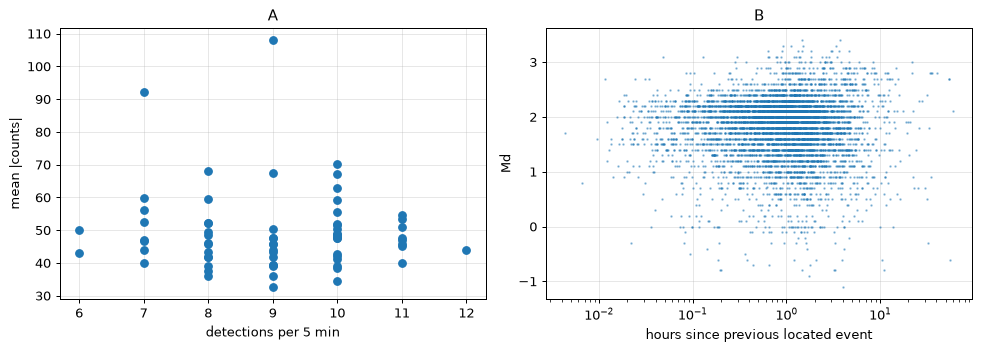

In [32]:
# A: 5-minute bins of the real record
parts = []
for tr in st:
    a = np.abs(tr.data.astype(float) - np.median(tr.data))
    parts.append(pd.DataFrame({"a": a, "loud": a > 3000},
                              index=pd.date_range(tr.stats.starttime.datetime, periods=tr.stats.npts, freq="10ms")))
amp5 = pd.concat(parts).resample("5min").agg({"a": ["mean", "count"], "loud": "sum"})
n5 = det.set_index("time")["peak"].resample("5min").count()
A = pd.DataFrame({"detections": n5, "mean_abs_counts": amp5[("a", "mean")], "samples": amp5[("a", "count")],
                  "loud_samples": amp5[("loud", "sum")]}).dropna()
A = A[A["samples"] >= 29900]                                   # keep only complete bins
rA, sA = stats.pearsonr(A["detections"], A["mean_abs_counts"])[0], stats.spearmanr(A["detections"], A["mean_abs_counts"])[0]
r1 = A["mean_abs_counts"].autocorr(1)
print(f"A: {len(A)} complete bins, Pearson {rA:.3f}, Spearman {sA:.3f}; lag-1 autocorrelation of amplitude {r1:.2f},")
print(f"   effective number of independent bins about {len(A) * (1 - r1) / (1 + r1):.0f}")
disp = A["detections"].var() / A["detections"].mean()
print(f"   detections per bin: {A['detections'].min()} to {A['detections'].max()}, mean {A['detections'].mean():.1f}, "
      f"variance / mean {disp:.2f} (a random Poisson count gives 1)")
Aq = A[A["loud_samples"] == 0]
print(f"   without the {len(A) - len(Aq)} bins holding samples beyond ±3000 counts: Pearson {stats.pearsonr(Aq['detections'], Aq['mean_abs_counts'])[0]:.3f}, "
      f"Spearman {stats.spearmanr(Aq['detections'], Aq['mean_abs_counts'])[0]:.3f}")

# B: catalog, 16 October 2004 to the end of 2005
B = cat[(cat["time"] >= "2004-10-16") & (cat["time"] < "2006-01-01") & (cat["type"] == "earthquake")].copy()
B["wait_h"] = B["time"].diff().dt.total_seconds() / 3600
B = B.dropna(subset=["wait_h"])
rB, sB = stats.pearsonr(B["mag"], B["wait_h"])[0], stats.spearmanr(B["mag"], B["wait_h"])[0]
print(f"B: {len(B)} located earthquakes, Pearson {rB:.3f}, Spearman {sB:.3f}")
print(f"   located per day: {len(B) / ((B['time'].max() - B['time'].min()).days):.1f}; the detector at HSR counts about {rate * 24:.0f} per day")

fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 4))
a1.plot(A["detections"], A["mean_abs_counts"], "o"); a1.set(xlabel="detections per 5 min", ylabel="mean |counts|", title="A")
a2.semilogx(B["wait_h"], B["mag"], ".", ms=2, alpha=0.4); a2.set(xlabel="hours since previous located event", ylabel="Md", title="B")
plt.tight_layout()

Traps: (a) a shared seasonal cycle; (b) catalog completeness: only part of the earthquakes are listed; (c) overlapping events: a large earthquake's coda covers nearby drumbeats; (d) a unit change; (e) the count barely varies between bins (a clock), leaving little variance to correlate.

In [33]:
q6_pearsonA = None      # Pearson r for A
q6_spearmanB = None     # Spearman rho for B
q6_trapA = None         # letter of the trap that matters most for A
q6_trapB = None         # letter of the trap that matters most for B
q6_says = """
"""                       # what do A and B say, and not say, about the drumbeat source?
check("6.pearsonA", q6_pearsonA, truth=rA); check("6.spearmanB", q6_spearmanB, truth=sB)
check("6.trapA", q6_trapA); check("6.trapB", q6_trapB)
check_text("6.says", q6_says, {"what a correlation near zero means here": r"zero|no correlation|weak|independent|not related|uncorrelated",
                               "cause and the regular clock": r"clock|regular|steady|constant|rate",
                               "what the catalog misses": r"complete|subset|missing|located|catalog"})

[6.pearsonA] not answered yet
[6.spearmanB] not answered yet
[6.trapA] not answered yet
[6.trapB] not answered yet
[6.says] not answered yet


*Worked solution below (click ⋯ to open).*

In [34]:
# Worked solution, open after you tried
print(f"A: Pearson {rA:.2f}, Spearman {sA:.2f}. Expected positive (more earthquakes, more shaking), observed near zero.")
print(f"The count per 5 minutes runs only from {A['detections'].min()} to {A['detections'].max()} (variance / mean {disp:.2f}, far below a")
print("random count's 1): a clock leaves almost no variance to correlate (e). The loud bins are set by a few large")
print(f"earthquakes and telemetry bursts, but removing them leaves the correlation near zero, so overlapping events (c)")
print("are a smaller effect. Accept (c) or (e); (e) drives the number. Only about", round(len(A) * (1 - r1) / (1 + r1)), "bins are independent.")
print()
print("B: expected sign '+'. Moran and others (p. 40): 'In general, increases in event spacing corresponded to increases in")
print("event size and vice versa (fig. 15)'. They saw it in daily averages of 'Roughly 370,000 events' detected at HSR")
print(f"(fig. 13 caption, p. 39). Here: Spearman {sB:.3f}, near zero, from {len(B)} located events.")
print(f"ComCat located about {len(B) / ((B['time'].max() - B['time'].min()).days):.0f} per day out of about {rate * 24:.0f} detected at HSR: 'time since the")
print("previous located event' is not the time since the previous earthquake. Completeness (b), plus the averaging scale:")
print("Moran's relation is between daily averages, not between single events.")
print("Neither result says the drumbeats have no memory: the catalog cannot test it, a full detection list could.")

A: Pearson -0.06, Spearman 0.02. Expected positive (more earthquakes, more shaking), observed near zero.
The count per 5 minutes runs only from 6 to 12 (variance / mean 0.21, far below a
random count's 1): a clock leaves almost no variance to correlate (e). The loud bins are set by a few large
earthquakes and telemetry bursts, but removing them leaves the correlation near zero, so overlapping events (c)
are a smaller effect. Accept (c) or (e); (e) drives the number. Only about 46 bins are independent.

B: expected sign '+'. Moran and others (p. 40): 'In general, increases in event spacing corresponded to increases in
event size and vice versa (fig. 15)'. They saw it in daily averages of 'Roughly 370,000 events' detected at HSR
(fig. 13 caption, p. 39). Here: Spearman -0.009, near zero, from 6669 located events.
ComCat located about 15 per day out of about 2607 detected at HSR: 'time since the
previous located event' is not the time since the previous earthquake. Completeness (b), plus 

```{admonition} If you are stuck
:class: hint
- `det` undefined: run the detector cell in Part 3.
- Pearson and Spearman differ in sign: both are near zero, so the sign is noise.
```

## Part 7. From data to a learning problem (10 min)

**Do:** write the chain from raw file to a learnable table, choose the task, look at the target, balance. Eight questions.

Could a day of catalog data tell whether the volcano is erupting, or predict an earthquake's magnitude? Write your chain as ordered `(step, reason)` pairs: what you select, remove, flag, keep as a real extreme, how you aggregate, which anomalies you compute, and how you split so nothing leaks from test to training.

In [35]:
q7_steps = [
    # ("select the box around the vent and event type 'earthquake'", "the explosion row is not an earthquake"),
]
check_pipeline(q7_steps)

q7_task = None      # "classification", "regression", "detection", "forecasting" or "clustering"
q7_target = None    # what is the target or label, in words
check("7.task", q7_task, target=q7_target)

[7.steps] not answered yet
[7.task] not answered yet


**Classification: a rare class.** The Puget Sound copy of ComCat (2000 to 2025, notebook 2.7) covers the same box. Count earthquakes per day; label days from 16 October 2004 to 31 January 2008 "dome-building eruption" (Dzurisin and others describe "repetitive 'drumbeat' earthquakes that characterized much of the eruption"). The drumbeats were not uniform: they "became irregular" on 20 July 2005, and by October 2005 Moran and others questioned "whether the seismic events we were seeing were earthquakes" (p. 39). The swarm and explosions of 23 September to 15 October 2004 are neither background nor dome building: dropped.

The Puget copy holds earthquakes of magnitude 0 or more, and "By September 24, earthquakes had become so numerous that the PNSN began locating only a subset of them" (p. 30): located earthquakes per day also measure analyst capacity and station coverage, which changed with the label.

In [36]:
pug = pd.read_csv(SNAP / "comcat_puget_2000-2025.csv", parse_dates=["time"])
pq = json.loads((SNAP / "comcat_puget_2000-2025.provenance.json").read_text())
print("Puget copy query:", {k: v for k, v in pq["query"].items() if k in ("eventtype", "minmagnitude")})
box = pug[pug["latitude"].between(46.10, 46.30) & pug["longitude"].between(-122.32, -122.08)]
in0408 = ((box["time"] >= "2004-01-01") & (box["time"] < "2009-01-01")).sum()
print(f"rows in the box for 2004-2008: {in0408} in the Puget copy, {len(cat)} in the Mount St Helens copy")
days = pd.date_range("2000-01-01", "2025-12-31", freq="D", tz="UTC")
daily = box.set_index("time").resample("D").size().reindex(days, fill_value=0).to_frame("n_events")
for a_, b_ in [("2000-01-01", "2004-09-23"), ("2004-09-23", "2004-10-16"), ("2004-10-16", "2006-01-01"),
               ("2006-01-01", "2008-02-01"), ("2008-02-01", "2016-01-01"), ("2016-01-01", "2026-01-01")]:
    seg = daily.loc[(daily.index >= pd.Timestamp(a_, tz="UTC")) & (daily.index < pd.Timestamp(b_, tz="UTC")), "n_events"]
    print(f"  {a_} to {b_}: {len(seg):5d} days, {seg.mean():6.2f} located per day, {(seg > 0).mean():.2f} of days with one or more")
daily = daily[(daily.index < pd.Timestamp("2004-09-23", tz="UTC")) | (daily.index >= pd.Timestamp("2004-10-16", tz="UTC"))]
daily["erupting"] = (daily.index >= pd.Timestamp("2004-10-16", tz="UTC")) & (daily.index < pd.Timestamp("2008-02-01", tz="UTC"))
frac_pos = daily["erupting"].mean()
split = pd.Timestamp("2016-01-01", tz="UTC")
train, test = daily[daily.index < split], daily[daily.index >= split]
print(f"{len(daily)} days kept, {daily['erupting'].sum()} in the dome-building eruption ({frac_pos:.2%})")
print(f"a model that always says 'not erupting' is right on {1 - frac_pos:.2%} of days")
print(f"time split, train 2000-2015 / test 2016-2025: {train['erupting'].sum()} / {test['erupting'].sum()} eruption days")
w_pos = (~train["erupting"]).sum() / train["erupting"].sum()
print(f"class weight for eruption days, computed on the training set only: {w_pos:.1f}")

Puget copy query: {'eventtype': 'earthquake', 'minmagnitude': 0}
rows in the box for 2004-2008: 10645 in the Puget copy, 11305 in the Mount St Helens copy
  2000-01-01 to 2004-09-23:  1727 days,   0.34 located per day, 0.25 of days with one or more
  2004-09-23 to 2004-10-16:    23 days,  87.39 located per day, 1.00 of days with one or more
  2004-10-16 to 2006-01-01:   442 days,  14.98 located per day, 0.98 of days with one or more
  2006-01-01 to 2008-02-01:   761 days,   2.40 located per day, 0.81 of days with one or more
  2008-02-01 to 2016-01-01:  2891 days,   0.64 located per day, 0.38 of days with one or more
  2016-01-01 to 2026-01-01:  3653 days,   0.97 located per day, 0.47 of days with one or more
9474 days kept, 1203 in the dome-building eruption (12.70%)
a model that always says 'not erupting' is right on 87.30% of days
time split, train 2000-2015 / test 2016-2025: 1203 / 0 eruption days
class weight for eruption days, computed on the training set only: 3.8


**Regression: a skewed target.** Large earthquakes are rare. A model trained with equal weights learns the common sizes and can be poor where it matters.

In [37]:
bins = np.arange(-2.5, 4.5, 0.5)
counts, _ = np.histogram(cat["mag"], bins=bins)
print(pd.Series(counts, index=[f"{a:.1f} to {a + 0.5:.1f}" for a in bins[:-1]]).to_string())
frac_big = (cat["mag"] >= 2.5).mean()
print(f"share of earthquakes with Md 2.5 or more: {frac_big:.3f}")
tr_m = cat.loc[cat["time"] < "2005-07-01", "mag"]                  # a time split for the regression
h, _ = np.histogram(tr_m, bins=bins)
weights = pd.Series(np.where(h > 0, len(tr_m) / (len(h) * np.maximum(h, 1)), 0), index=bins[:-1]).round(2)
print("weight per magnitude bin, computed on the training rows only:", weights[weights > 0].to_dict())

-2.5 to -2.0       1
-2.0 to -1.5       9
-1.5 to -1.0      40
-1.0 to -0.5     197
-0.5 to 0.0      412
0.0 to 0.5       464
0.5 to 1.0       770
1.0 to 1.5      1618
1.5 to 2.0      2946
2.0 to 2.5      3456
2.5 to 3.0       996
3.0 to 3.5       377
3.5 to 4.0        19
share of earthquakes with Md 2.5 or more: 0.123
weight per magnitude bin, computed on the training rows only: {-2.5: 610.31, -2.0: 67.81, -1.5: 16.95, -1.0: 3.74, -0.5: 2.41, 0.0: 2.01, 0.5: 1.3, 1.0: 0.62, 1.5: 0.31, 2.0: 0.22, 2.5: 0.96, 3.0: 2.22, 3.5: 40.69}


In [38]:
q7_frac = None          # fraction of eruption days among the days kept, 2000-2025
q7_acc = None           # accuracy of a model that always says "not erupting"
q7_test_pos = None      # eruption days in the 2016-2025 test set
q7_big = None           # share of earthquakes with Md 2.5 or more
q7_balance = """
"""                       # how would you balance each problem, when, on which data, and what does it change?
check("7.frac", q7_frac, truth=frac_pos); check("7.acc", q7_acc, truth=1 - frac_pos)
check("7.test", q7_test_pos, truth=int(test["erupting"].sum())); check("7.big", q7_big, truth=frac_big)
check_text("7.balance", q7_balance, {"when balancing happens": r"after (the )?split|training (set|data) only|only on (the )?train",
                                      "how to measure a rare class": r"recall|precision|f1|pr curve|precision-recall",
                                      "what balancing changes": r"base rate|prior|calibrat|probabilit",
                                      "the regression extremes": r"quantile|bin|weight|extreme|large"})

[7.frac] not answered yet
[7.acc] not answered yet
[7.test] not answered yet
[7.big] not answered yet
[7.balance] not answered yet


*Worked solution below (click ⋯ to open).*

In [39]:
# Worked solution, open after you tried
print(f"eruption days {frac_pos:.4f}; always-'not erupting' accuracy {1 - frac_pos:.4f}: accuracy says little here.")
print(f"A time split at 2016 leaves {int(test['erupting'].sum())} eruption days to test on: one eruption cannot be split")
print("in time and still be tested. Options: split within 2004-2008 by blocks of weeks with a buffer between them")
print("(the days are autocorrelated), or test on another eruption or volcano.")
print("The feature is not stationary: located events per day were higher after 2016 than before September 2004 (table above),")
print("while the volcano was quiet in both periods. A model can learn the network's history as well as the volcano's.")
print(f"Balancing comes after the split and only on the training data: class weights (here about {w_pos:.0f}),")
print("or resampling the training days. Report recall and the precision-recall curve on the untouched test set.")
print("Weighting changes the base rate the model learns, so its probabilities must be recalibrated before use.")
print(f"Regression: {frac_big:.1%} of magnitudes are 2.5 or more. Weight by magnitude bin (computed on training rows),")
print("stratify validation folds by magnitude quantile, and report the error per quantile, not one overall RMSE.")
print("Bins holding one or a few events get weights of tens to hundreds: merge sparse bins or cap the weights.")
print("Clipping at HSR and the coda bias of Md for drumbeats mean the largest targets are themselves uncertain.")
sol_steps = [("select the box, type 'earthquake' and magnitude 0 or more, and write the selection down", "the Puget copy was queried this way; the 2008 explosion row is not an earthquake"),
             ("keep rows sharing an origin time but flag them", "one may be a mis-association; decide with waveforms"),
             ("resample to daily counts, fill missing days with 0", "a day without located events is a real zero here"),
             ("drop 23 September to 15 October 2004", "swarm and explosions: neither background nor dome building"),
             ("label days from the dates of Dzurisin and others (2015)", "the label must come from an independent source"),
             ("note when the network changed how it located events", "the count measures analyst capacity as well as the volcano"),
             ("split by time blocks with a buffer", "neighboring days share the same unrest"),
             ("compute class weights on the training set", "balancing after the split, on training data only"),
             ("evaluate recall and precision on the untouched test set", "accuracy hides a rare class")]
check_pipeline(sol_steps, record=False)

eruption days 0.1270; always-'not erupting' accuracy 0.8730: accuracy says little here.
A time split at 2016 leaves 0 eruption days to test on: one eruption cannot be split
in time and still be tested. Options: split within 2004-2008 by blocks of weeks with a buffer between them
(the days are autocorrelated), or test on another eruption or volcano.
The feature is not stationary: located events per day were higher after 2016 than before September 2004 (table above),
while the volcano was quiet in both periods. A model can learn the network's history as well as the volcano's.
Balancing comes after the split and only on the training data: class weights (here about 4),
or resampling the training days. Report recall and the precision-recall curve on the untouched test set.
Weighting changes the base rate the model learns, so its probabilities must be recalibrated before use.
Regression: 12.3% of magnitudes are 2.5 or more. Weight by magnitude bin (computed on training rows),
stratify valida

```{admonition} If you are stuck
:class: hint
- 'order of splitting and balancing': weighting or resampling the training data comes after the split; resampling events to daily counts is aggregation and comes before.
- `json` undefined: run the first code cell again.
```

## Part 8. Instructions for an AI tool (7 min, if you have time)

**Do:** start the instruction files you submit, try them on an AI tool, compare its findings on your twin with yours. Two questions.

```{admonition} 🔍 Agent, then verify
:class: important
An AI tool does this step. You accept its result only after your own checks pass, and you record the conversation in `ai_conversation.md` (template in `lab_s07_templates/`; [1.8](../Chapter1-GettingStarted/1.8_ai_in_your_workflow.md)).
```

Templates with volcano hints are in `lab_s07_templates/`:
- `reproducibility_rules.md`: rules, each checkable yes or no, that an AI tool must follow on your project data, built on the six AGENTS.md headings of HW1 ([1.9](../Chapter1-GettingStarted/1.9_workbench_setup_hw1.md), Step 7) and the class rubric.
- `pipeline_instructions.md`: from raw ComCat and HSR files to the drumbeat clock: get the files from the providers, confirm they were not modified or corrupted, clean with a reason per step (flag, remove, or keep a real extreme), compute the clock, report what the tool could not do.
- `ai_conversation.md` (the transcript may be a PDF beside it): the record of your conversation, and what you checked and corrected.

UW Purple cannot run code or read MiniSEED: upload your two instruction files and the CSV files written below. Claude or GitHub Copilot in VS Code open files directly. In class, give the tool the twin files and the instructions below; enter its findings in the same format as yours. The twin test stays in this notebook (`tool_findings`, `q8`); item (d) is a separate conversation on the real data with your two files. The last cell of this part prints the real-data values to compare the tool's numbers with.

In [40]:
paths = twin.write_files(DL)
# CSV copy of the real HSR record for tools that cannot read MiniSEED: min, max and mean count per second
real = pd.concat([pd.Series(tr.data, index=pd.date_range(tr.stats.starttime.datetime, periods=tr.stats.npts, freq="10ms"))
                  for tr in st]).resample("1s").agg(["min", "max", "mean", "count"]).dropna()
real.round(1).to_csv(DL / "s07_volcano_HSR_2004-11-29_1s.csv", index_label="time")
print("files for the AI tool:", paths)
print("real data as CSV:", DL / "s07_volcano_HSR_2004-11-29_1s.csv", "and", course["catalog"])
print()
print(twin.instructions(paths))

files for the AI tool: {'mseed': 's07_my_files/s07_volcano_HSR_class_seismogram.mseed', 'csv1s': 's07_my_files/s07_volcano_HSR_class_seismogram_1s.csv', 'events': 's07_my_files/s07_volcano_HSR_class_events.csv'}
real data as CSV: s07_my_files/s07_volcano_HSR_2004-11-29_1s.csv and snapshots/comcat_msh_2004-2008.csv

I attach two files from a short-period vertical seismometer 2.5 km from an erupting lava dome:
(1) s07_volcano_HSR_class_seismogram.mseed (MiniSEED, 100 samples per second, raw counts; if you cannot read MiniSEED use s07_volcano_HSR_class_seismogram_1s.csv, which
gives for each second the minimum, maximum and mean count and the number of samples), and
(2) s07_volcano_HSR_class_events.csv (the list of events built from this record: time in UTC, peak amplitude in counts within 6 s
of the onset, duration magnitude, magnitude type, id).
The files contain problems introduced by the instrument, the telemetry, the clock, or the people and programs
that built the event list. List ev

In [41]:
tool_findings = [
    # {"kind": "dropout", "minute": 47.5, "why": "as the tool said it"},
]
tool_cv = {"before": None, "after": None}      # the CVs the tool reports
if tool_findings:
    twin.score(tool_findings, who="AI tool", show_missed=True)
    twin.score(findings, who="you", show_missed=True)
    print(three[["cv"]].assign(tool=[None, tool_cv["before"], tool_cv["after"]]).to_string())
else:
    print("not answered yet")
q8 = """
"""           # what did the tool miss, what did it invent, did it treat a real large earthquake as an error?
check_text("8", q8, {"what it missed": r"miss", "what it invented": r"invent|false|not planted|wrong|made up",
                     "the real earthquakes": r"real|earthquake|extreme"})

not answered yet
[8] not answered yet


In [42]:
# Reference values on the real HSR record (Part 3), for pipeline_instructions.md and ai_conversation.md.
# The twin numbers of Part 5 are not these.
def spacing_cv(times):
    gaps = pd.Series(pd.to_datetime(times)).sort_values().diff().dt.total_seconds()
    gaps = gaps[gaps < 600]                      # skip the interval that spans the 20.3-minute data gap
    return gaps.std() / gaps.mean(), gaps.median(), len(gaps)

at_burst = np.zeros(len(det), bool)               # detections within 3 s of a telemetry burst (Part 3)
for b in bursts_hsr:
    at_burst |= (pd.to_datetime(det["time"]) - b).abs().dt.total_seconds().values < 3
for label, sel in (("every detection, as read", np.ones(len(det), bool)),
                   ("detections at telemetry bursts removed", ~at_burst)):
    cv_, med_, n_ = spacing_cv(det.loc[sel, "time"])
    print(f"real data, {label}: CV of the spacing {cv_:.3f}, median spacing {med_:.1f} s, {n_} intervals")

real data, every detection, as read: CV of the spacing 0.371, median spacing 34.5 s, 613 intervals
real data, detections at telemetry bursts removed: CV of the spacing 0.374, median spacing 34.7 s, 606 intervals


```{admonition} If you are stuck
:class: hint
- The tool cannot open MiniSEED: give it the `_seismogram_1s.csv` file.
- The tool reports clock times: subtract the twin's start (Part 5) and convert to minutes.
```

## Wrap-up (3 min)

Three answers, two to four sentences each, each with one number or date from today's work. Then Kernel, Restart Kernel and Run All Cells; read the summary at the end, save, and submit.

In [43]:
w1 = """
"""   # What physical process makes the drumbeats, and which feature of the HSR record shows it?
w2 = """
"""   # Which step between the ground and the catalog most limits what you can learn about the drumbeat clock, and why?
w3 = """
"""   # Which problem in your twin could cleaning not undo, and what extra data would recover it?
check_text("w1", w1, {"the source process": r"spine|extru|plug|stick|slip|magma|dome|conduit",
                      "evidence in the record": r"regular|interval|spacing|clock|repeat|similar|low.frequency"}, min_words=20)
check_text("w2", w2, {"a step in the chain": r"clip|range|digitiz|locat|catalog|detect|complete|telemetry|gain"}, min_words=20)
check_text("w3", w3, {"what is lost": r"lost|cannot|missing|gap|zero|dropout|clip",
                      "what would recover it": r"station|another|second|metadata|broadband|independent|backup"}, min_words=20)

[w1] not answered yet
[w2] not answered yet
[w3] not answered yet


In [44]:
print_summary(globals())

==== SESSION 7 SUMMARY ====
track: volcano
netid: not answered
parts answered: P0 0/1 | P1 0/6 | P2 0/5 | P3 0/5 | P4 0/4 | P5 0/4 | P6 0/6 | P7 0/8 | P8 0/2
self-checks passed: 0 of 37
planted problems found: 0 of 6 (seed 4286574832)
derived quantity (truth / as given / after cleaning): 0.152 / 1.601 / not answered (CV of the drumbeat spacing, no unit)
reflection 1: not answered
reflection 2: not answered
reflection 3: not answered
==== END SUMMARY ====
